# Clinical prediction and survival analysis on a simulated Alzheimer's cohort

An end-to-end walkthrough from a relational clinical database to prediction models,
model explanation, and time-to-event analysis with competing risks.

> ⚠️ **All data in this notebook is synthetic.**
> The cohort is generated in section 2 from a fixed random seed. No real patient data
> is used at any point, and nothing below is a clinical finding. The purpose is to
> demonstrate an analysis pipeline on data whose ground truth is known by construction.

**How to run.** Execute from the top. Section 2 writes `alzheimer_cohort.db` into the
working directory, so no download is needed. The seed is fixed, so every run reproduces
the same numbers.

**Requirements.** See `requirements.txt` in the repository. On Colab, uncomment the
setup cell below; locally, prefer `pip install -r requirements.txt`.

### Contents

**Part 1. Data and prediction**

| Sections | Topic                                                                        |
| -------- | ---------------------------------------------------------------------------- |
| 1 to 3   | Imports, building the database, loading it with SQL                          |
| 4 to 5   | Data quality, long to wide, baseline cohort table                            |
| 6 to 9   | Table 1, MMSE trajectories, risk factors, correlation structure              |
| 10 to 11 | Outcome definition, leakage check, stratified split                          |
| 12 to 15 | Logistic regression, XGBoost, LightGBM, CatBoost                             |
| 16       | Final test-set evaluation: ROC, precision-recall, calibration, bootstrap CIs |
| 17       | SHAP: global beeswarm and an individual waterfall                            |

**Part 2. Survival analysis**

| Sections | Topic                                                 |
| -------- | ----------------------------------------------------- |
| 18       | Time-to-event dataset for all 2,000 patients          |
| 19       | Cumulative incidence with death as a competing risk   |
| 20       | Cause-specific Cox model for Alzheimer's              |
| 21       | Testing the proportional hazards assumption           |
| 22       | Cox model for the competing event, with a forest plot |

---

## 0. Setup: install libraries


In [1]:
# Colab or a fresh environment only.
# Locally, use: pip install -r requirements.txt
# %pip install -q xgboost lightgbm catboost shap statsmodels ipywidgets

## 1. Import libraries


In [2]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
import lightgbm
import catboost
import shap

for lib in [np, pd, sns, sklearn, xgboost, lightgbm, catboost, shap]:
    print(f"{lib.__name__:<10} {lib.__version__}")

c:\Users\Anna\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


numpy      2.3.5
pandas     3.0.5
seaborn    0.13.2
sklearn    1.9.0
xgboost    3.4.1
lightgbm   4.7.0
catboost   1.2.10
shap       0.54.1


## 2. Build the simulated database

2,000 patients aged 60–80, enrolled in 2014–2015, with annual visits for up to 10 years.
Follow-up ends at Alzheimer's diagnosis, death, or loss to follow-up.
Saved as a SQLite database with 4 tables: `patients`, `visits`, `labs`, `events`.


In [3]:
rng = np.random.default_rng(2026)   # fixed seed -> same data every run
N = 2000
STUDY_START = pd.Timestamp("2014-01-01")
LAB_TESTS = {  # test: (unit, mean, sd)
    "glucose": ("mg/dL", 100, 18),
    "hba1c": ("%", 5.8, 0.7),
    "ldl": ("mg/dL", 125, 32),
    "hdl": ("mg/dL", 52, 13),
    "creatinine": ("mg/dL", 0.95, 0.22),
    "vitamin_b12": ("pg/mL", 450, 160),
    "homocysteine": ("umol/L", 12, 3.5),
    "crp": ("mg/L", 3, 2.5),
}

# ---------- patients (identification + fixed characteristics) ----------
pid = [f"ALZ-{i:05d}" for i in range(1, N + 1)]
enroll = STUDY_START + pd.to_timedelta(rng.integers(0, 730, N), unit="D")
age0 = rng.uniform(60, 80, N)
patients = pd.DataFrame({
    "patient_id": pid,
    "sex": rng.choice(["F", "M"], N, p=[0.55, 0.45]),
    "birth_date": (enroll - pd.to_timedelta(age0 * 365.25, unit="D")).normalize(),
    "education_years": np.clip(rng.normal(11, 4, N).round(), 0, 22).astype(int),
    "apoe4_alleles": rng.choice([0, 1, 2], N, p=[0.70, 0.25, 0.05]),
    "smoking": rng.choice(["never", "former", "current"], N, p=[0.5, 0.35, 0.15]),
    "site": rng.choice(["Site A", "Site B", "Site C"], N),
    "enrollment_date": enroll.normalize(),
})

# chronic conditions at baseline (can also appear later)
diab = rng.random(N) < 0.18
htn = rng.random(N) < 0.45
dep = rng.random(N) < 0.12
# each patient has their own typical lab value ("set point")
lab_base = {t: rng.normal(m, s, N) for t, (_, m, s) in LAB_TESTS.items()}
lab_base["glucose"] += diab * 35
lab_base["hba1c"] += diab * 1.4
lab_base["homocysteine"] += (lab_base["vitamin_b12"] < 300) * 3

# ---------- annual follow-up (up to 10 years) ----------
visits, labs, events = [], [], []
vid = 0
for i in range(N):
    mmse = np.clip(rng.normal(
        28.5 - 0.08 * (age0[i] - 70) + 0.1 * (patients.education_years[i] - 11), 1.0), 22, 30)
    # MMSE points lost per year
    decline = 0.15 + 0.35 * patients.apoe4_alleles[i] + 0.2 * diab[i]
    bmi = rng.normal(27, 4)
    for year in range(11):
        age = age0[i] + year
        vid += 1
        # baseline visit = enrollment day
        jitter = 0 if year == 0 else int(rng.integers(-30, 31))
        vdate = (patients.enrollment_date[i] + pd.Timedelta(
            days=int(365.25 * year) + jitter)).normalize()
        if year > 0:
            diab[i] |= rng.random() < 0.012
            htn[i] |= rng.random() < 0.025
            dep[i] |= rng.random() < 0.01
        visits.append({
            "visit_id": vid, "patient_id": pid[i], "visit_date": vdate, "visit_year": year,
            "mmse": int(round(np.clip(mmse - decline * year + rng.normal(0, 0.8), 0, 30))),
            "bmi": round(bmi + rng.normal(0, 0.6) - 0.05 * year, 1),
            "systolic_bp": int(rng.normal(132 + 14 * htn[i], 12)),
            "diabetes": int(diab[i]), "hypertension": int(htn[i]), "depression": int(dep[i]),
        })
        for t, (unit, _, s) in LAB_TESTS.items():
            if rng.random() < 0.08:           # ~8% of tests not done at a visit
                continue
            val = lab_base[t][i] + rng.normal(0, 0.25 * s) + \
                (0.3 * year if t == "homocysteine" else 0)
            labs.append({"visit_id": vid, "patient_id": pid[i], "test_name": t,
                         "value": round(max(val, 0.1), 2), "unit": unit})

        # events between visits: Alzheimer's, death, lost to follow-up
        if year == 10:
            break
        hcy = lab_base["homocysteine"][i]
        logit_ad = (-6.0 + 0.10 * (age - 70) + 0.95 * patients.apoe4_alleles[i]
                    - 0.06 *
                    (patients.education_years[i] - 11) +
                    0.5 * diab[i] + 0.35 * htn[i]
                    + 0.5 * dep[i] + 0.06 * (hcy - 12) + 0.15 * (28 - visits[-1]["mmse"]))
        edate = vdate + pd.Timedelta(days=int(rng.integers(30, 330)))
        if rng.random() < 1 / (1 + np.exp(-logit_ad)):
            events.append(
                {"patient_id": pid[i], "event_type": "alzheimer", "event_date": edate})
            break
        if rng.random() < 0.004 * np.exp(0.09 * (age - 70)) * 4:
            events.append(
                {"patient_id": pid[i], "event_type": "death", "event_date": edate})
            break
        if rng.random() < 0.03:
            events.append(
                {"patient_id": pid[i], "event_type": "lost_to_followup", "event_date": edate})
            break

visits = pd.DataFrame(visits)
labs = pd.DataFrame(labs)
events = pd.DataFrame(events)

# ---------- save as a SQLite database (4 related tables) ----------
with sqlite3.connect("alzheimer_cohort.db") as con:
    for name, table in {"patients": patients, "visits": visits, "labs": labs, "events": events}.items():
        out = table.copy()
        for c in out.select_dtypes("datetime").columns:
            # dates stored as ISO text
            out[c] = out[c].dt.strftime("%Y-%m-%d")
        out.to_sql(name, con, if_exists="replace", index=False)

print(
    f"patients: {len(patients)} | visits: {len(visits)} | labs: {len(labs)} | events: {len(events)}")
print(events["event_type"].value_counts())

patients: 2000 | visits: 15832 | labs: 116449 | events: 1102
event_type
lost_to_followup    470
death               389
alzheimer           243
Name: count, dtype: int64


## 3. Load data from the database

Read each table with SQL. Dates are stored as text in SQLite, so we convert them on load.


In [4]:
# Which columns are dates in each table
DATE_COLS = {
    "patients": ["birth_date", "enrollment_date"],
    "visits": ["visit_date"],
    "labs": [],
    "events": ["event_date"],
}

with sqlite3.connect("alzheimer_cohort.db") as con:
    tables = pd.read_sql(
        "SELECT name FROM sqlite_master WHERE type = 'table'", con)
    db = {t: pd.read_sql(f"SELECT * FROM {t}", con, parse_dates=cols)
          for t, cols in DATE_COLS.items()}

print("Tables in the database:", list(tables["name"]))

for name, df in db.items():
    print(f"\n=== {name}: {df.shape[0]:,} rows x {df.shape[1]} columns")
    display(df.head(3))

Tables in the database: ['patients', 'visits', 'labs', 'events']

=== patients: 2,000 rows x 8 columns


,patient_id,sex,birth_date,education_years,apoe4_alleles,smoking,site,enrollment_date
0,ALZ-00001,F,1939-08-19,16,0,former,Site B,2015-09-14
1,ALZ-00002,F,1952-06-05,6,0,never,Site B,2014-05-11
2,ALZ-00003,F,1940-01-04,5,0,never,Site C,2014-01-20



=== visits: 15,832 rows x 10 columns


,visit_id,patient_id,visit_date,visit_year,mmse,bmi,systolic_bp,diabetes,hypertension,depression
0,1,ALZ-00001,2015-09-14,0,30,24.4,142,0,1,0
1,2,ALZ-00001,2016-09-06,1,28,25.4,151,0,1,0
2,3,ALZ-00001,2017-09-24,2,29,25.2,160,0,1,0



=== labs: 116,449 rows x 5 columns


,visit_id,patient_id,test_name,value,unit
0,1,ALZ-00001,glucose,93.01,mg/dL
1,1,ALZ-00001,hba1c,4.83,%
2,1,ALZ-00001,ldl,130.25,mg/dL



=== events: 1,102 rows x 3 columns


,patient_id,event_type,event_date
0,ALZ-00005,lost_to_followup,2019-12-16
1,ALZ-00006,lost_to_followup,2024-08-01
2,ALZ-00007,alzheimer,2019-10-15


### How did follow-up end for each patient?

No row in `events` = completed the 10 years with no event.


In [5]:
status = db["patients"][["patient_id"]].merge(
    db["events"], on="patient_id", how="left")
status["event_type"] = status["event_type"].fillna("completed_10_years")
status["event_type"].value_counts()

event_type
completed_10_years    898
lost_to_followup      470
death                 389
alzheimer             243
Name: count, dtype: int64

## 4. Data quality checks

Before any analysis: duplicates, links between tables, missing values, impossible values.


In [6]:
p, v, l, e = db["patients"], db["visits"], db["labs"], db["events"]

checks = {
    "duplicate patient_id in patients": p["patient_id"].duplicated().sum(),
    "duplicate visit_id in visits":     v["visit_id"].duplicated().sum(),
    "duplicate (patient, visit_year)":  v.duplicated(["patient_id", "visit_year"]).sum(),
    "visits from unknown patients":     (~v["patient_id"].isin(p["patient_id"])).sum(),
    "labs from unknown visits":         (~l["visit_id"].isin(v["visit_id"])).sum(),
    "events from unknown patients":     (~e["patient_id"].isin(p["patient_id"])).sum(),
    "missing values (all tables)":      sum(df.isna().sum().sum() for df in db.values()),
    "MMSE outside 0-30":                (~v["mmse"].between(0, 30)).sum(),
    "visit before enrollment":          v.merge(p, on="patient_id").eval("visit_date < enrollment_date").sum(),
}
display(pd.Series(checks, name="problems").to_frame())

# Lab completeness: how many of the possible tests were actually done?
possible = v["visit_id"].nunique() * l["test_name"].nunique()
print(
    f"Lab tests done: {len(l):,} of {possible:,} possible ({len(l) / possible:.1%})")

# Lab value ranges by test
l.groupby(["test_name", "unit"])["value"].describe()[
    ["count", "mean", "min", "50%", "max"]].round(2)

,problems
duplicate patient_id in patients,0
duplicate visit_id in visits,0
"duplicate (patient, visit_year)",0
visits from unknown patients,0
labs from unknown visits,0
events from unknown patients,0
missing values (all tables),0
MMSE outside 0-30,0
visit before enrollment,0


Lab tests done: 116,449 of 126,656 possible (91.9%)


,,count,mean,min,50%,max
test_name,unit,,,,,
creatinine,mg/dL,14528.0,0.95,0.13,0.95,1.80
crp,mg/L,14590.0,3.26,0.10,3.12,12.04
glucose,mg/dL,14581.0,106.85,35.99,105.09,189.83
hba1c,%,14558.0,6.05,3.48,5.99,9.22
hdl,mg/dL,14601.0,51.85,2.80,52.01,106.15
homocysteine,umol/L,14573.0,13.67,0.10,13.61,28.43
ldl,mg/dL,14501.0,125.51,0.10,125.29,271.62
vitamin_b12,pg/mL,14517.0,446.23,0.10,442.82,1068.18


### Long → wide: missing tests become visible


In [7]:
labs_wide = l.pivot(index="visit_id", columns="test_name", values="value")
print("shape:", labs_wide.shape)   # one row per visit, one column per test
display(labs_wide.head())
labs_wide.isna().sum()

shape: (15832, 8)


test_name,creatinine,crp,glucose,hba1c,hdl,homocysteine,ldl,vitamin_b12
visit_id,,,,,,,,
1,1.05,3.51,93.01,4.83,58.68,14.89,130.25,493.23
2,1.00,2.21,89.65,4.99,51.21,16.05,141.80,467.76
3,1.01,2.04,NaN,5.06,53.62,16.76,145.88,466.34
4,0.97,3.21,NaN,4.72,53.72,16.58,149.35,439.70
5,0.92,3.38,98.29,4.75,56.49,15.88,142.84,513.34


test_name
creatinine      1304
crp             1242
glucose         1251
hba1c           1274
hdl             1231
homocysteine    1259
ldl             1331
vitamin_b12     1315
dtype: int64

## 5. Baseline cohort table (one row per patient)

- Lab values outside physiological limits → missing
- Baseline = enrollment visit (year 0): demographics + clinical + labs
- Follow-up status and years of follow-up


In [8]:
# 1) Labs in wide format + plausibility limits
labs_wide = l.pivot(index="visit_id", columns="test_name", values="value")

PLAUSIBLE = {  # test: (low, high) physiologically possible range
    "glucose": (50, 600), "hba1c": (4, 15), "ldl": (20, 400), "hdl": (15, 150),
    "creatinine": (0.3, 15), "vitamin_b12": (100, 2000), "homocysteine": (3, 100), "crp": (0, 300),
}
labs_clean = labs_wide.copy()
for test, (low, high) in PLAUSIBLE.items():
    bad = labs_clean[test].notna() & ~labs_clean[test].between(low, high)
    labs_clean.loc[bad, test] = np.nan
    print(f"{test:<13} implausible -> missing: {bad.sum()}")

# 2) One row per patient: patients + baseline visit + baseline labs + event
baseline_visits = v[v["visit_year"] == 0].drop(columns="visit_year")
cohort = (
    p.merge(baseline_visits, on="patient_id", how="left")
     .merge(labs_clean, left_on="visit_id", right_index=True, how="left")
     .merge(e, on="patient_id", how="left")
)

# 3) Derived columns
cohort["age_baseline"] = (
    (cohort["enrollment_date"] - cohort["birth_date"]).dt.days / 365.25).round(1)
cohort["status"] = cohort["event_type"].fillna("completed_10_years")
last_visit = v.groupby("patient_id")["visit_date"].max()
cohort["end_date"] = cohort["event_date"].fillna(
    cohort["patient_id"].map(last_visit))
cohort["followup_years"] = (
    (cohort["end_date"] - cohort["enrollment_date"]).dt.days / 365.25).round(2)
cohort = cohort.drop(columns=["event_type", "visit_date", "visit_id"])

# 4) Checks
assert cohort["patient_id"].is_unique and len(cohort) == len(p)
print("\ncohort:", cohort.shape)
display(cohort.head(3).T)
cohort.groupby("status")["followup_years"].describe().round(1)

glucose       implausible -> missing: 37
hba1c         implausible -> missing: 61
ldl           implausible -> missing: 4
hdl           implausible -> missing: 59
creatinine    implausible -> missing: 34
vitamin_b12   implausible -> missing: 195
homocysteine  implausible -> missing: 40
crp           implausible -> missing: 0

cohort: (2000, 27)


,0,1,2
patient_id,ALZ-00001,ALZ-00002,ALZ-00003
sex,F,F,F
birth_date,1939-08-19 00:00:00,1952-06-05 00:00:00,1940-01-04 00:00:00
education_years,16,6,5
apoe4_alleles,0,0,0
smoking,former,never,never
site,Site B,Site B,Site C
enrollment_date,2015-09-14 00:00:00,2014-05-11 00:00:00,2014-01-20 00:00:00
mmse,30,29,26
bmi,24.4,26.3,28.1


,count,mean,std,min,25%,50%,75%,max
status,,,,,,,,
alzheimer,243.0,5.7,2.8,0.1,3.6,5.9,8.2,9.9
completed_10_years,898.0,10.0,0.0,9.9,10.0,10.0,10.0,10.1
death,389.0,5.0,2.9,0.2,2.6,5.1,7.5,9.9
lost_to_followup,470.0,4.3,2.8,0.1,2.0,3.9,6.5,9.9


### Following one patient through the tables


In [9]:
pid_example = "ALZ-00001"

print("1) visits of this patient (first 3):")
display(v[v["patient_id"] == pid_example]
        [["patient_id", "visit_year", "visit_id"]].head(3))

print("2) labs of visit_id 1 (the baseline visit):")
display(l[l["visit_id"] == 1][["visit_id", "patient_id", "test_name", "value"]])

print("3) result in the cohort table:")
cohort.loc[cohort["patient_id"] == pid_example, [
    "patient_id", "mmse", "glucose", "hba1c", "ldl"]]

1) visits of this patient (first 3):


,patient_id,visit_year,visit_id
0,ALZ-00001,0,1
1,ALZ-00001,1,2
2,ALZ-00001,2,3


2) labs of visit_id 1 (the baseline visit):


,visit_id,patient_id,test_name,value
0,1,ALZ-00001,glucose,93.01
1,1,ALZ-00001,hba1c,4.83
2,1,ALZ-00001,ldl,130.25
3,1,ALZ-00001,hdl,58.68
4,1,ALZ-00001,creatinine,1.05
5,1,ALZ-00001,vitamin_b12,493.23
6,1,ALZ-00001,homocysteine,14.89
7,1,ALZ-00001,crp,3.51


3) result in the cohort table:


,patient_id,mmse,glucose,hba1c,ldl
0,ALZ-00001,30,93.01,4.83,130.25


## 6. Table 1 – Baseline characteristics by follow-up status

Numeric: median [IQR]. Categorical: n (%).


In [10]:
NUMERIC = ["age_baseline", "education_years", "mmse", "bmi", "systolic_bp",
           "glucose", "hba1c", "ldl", "hdl", "creatinine", "vitamin_b12", "homocysteine", "crp"]
CATEGORICAL = ["sex", "apoe4_alleles", "smoking",
               "diabetes", "hypertension", "depression"]
ORDER = ["alzheimer", "death", "lost_to_followup",
         "completed_10_years", "Total"]


def median_iqr(x):
    q1, q2, q3 = x.quantile([0.25, 0.5, 0.75])
    return f"{q2:.1f} [{q1:.1f}–{q3:.1f}]"


groups = list(cohort.groupby("status")) + [("Total", cohort)]
rows = {("n", ""): {g: len(d) for g, d in groups}}

for col in NUMERIC:
    rows[(col, "median [IQR]")] = {g: median_iqr(d[col]) for g, d in groups}

for col in CATEGORICAL:
    for level in sorted(cohort[col].unique()):
        rows[(col, str(level))] = {
            g: f"{(d[col] == level).sum()} ({(d[col] == level).mean():.0%})" for g, d in groups
        }

table1 = pd.DataFrame(rows).T[ORDER]
display(table1)

print("Missing baseline lab values (excluded from medians):")
cohort[NUMERIC].isna().sum()[lambda s: s > 0]

,,alzheimer,death,lost_to_followup,completed_10_years,Total
n,,243,389,470,898,2000
age_baseline,median [IQR],73.5 [68.8–77.5],73.2 [68.2–76.7],68.7 [64.3–74.4],67.6 [63.7–72.8],69.6 [64.9–74.8]
education_years,median [IQR],10.0 [7.0–13.0],11.0 [8.0–14.0],12.0 [9.0–14.0],11.0 [8.0–14.0],11.0 [8.0–14.0]
mmse,median [IQR],28.0 [27.0–29.0],28.0 [28.0–29.0],29.0 [28.0–29.0],29.0 [28.0–30.0],29.0 [28.0–29.0]
bmi,median [IQR],27.0 [24.5–29.7],27.0 [23.8–29.7],26.9 [24.4–29.5],26.8 [24.2–29.7],26.9 [24.2–29.7]
systolic_bp,median [IQR],140.0 [130.0–149.5],138.0 [129.0–147.0],136.0 [127.0–146.0],138.0 [128.2–147.0],138.0 [128.0–147.0]
glucose,median [IQR],109.8 [92.7–121.7],102.2 [87.3–119.5],104.2 [87.7–119.5],104.9 [90.0–123.2],104.7 [89.7–121.4]
hba1c,median [IQR],6.0 [5.5–6.7],6.0 [5.4–6.6],6.0 [5.5–6.5],6.0 [5.4–6.6],6.0 [5.5–6.6]
ldl,median [IQR],123.1 [101.4–144.0],127.7 [104.3–149.7],121.2 [105.0–142.5],126.0 [104.1–147.2],125.0 [104.1–146.1]
hdl,median [IQR],53.1 [44.8–62.3],51.4 [42.4–59.9],53.0 [42.6–61.7],51.5 [42.7–61.0],52.0 [42.8–61.0]


Missing baseline lab values (excluded from medians):


glucose         148
hba1c           168
ldl             165
hdl             171
creatinine      186
vitamin_b12     200
homocysteine    143
crp             165
dtype: int64

## 7. Visualization – MMSE trajectories over follow-up

Uses **all visits**, not only the baseline.

- A: mean MMSE by year since enrollment, Alzheimer's vs. no Alzheimer's
- B: MMSE aligned to the date of diagnosis (only patients who developed Alzheimer's)


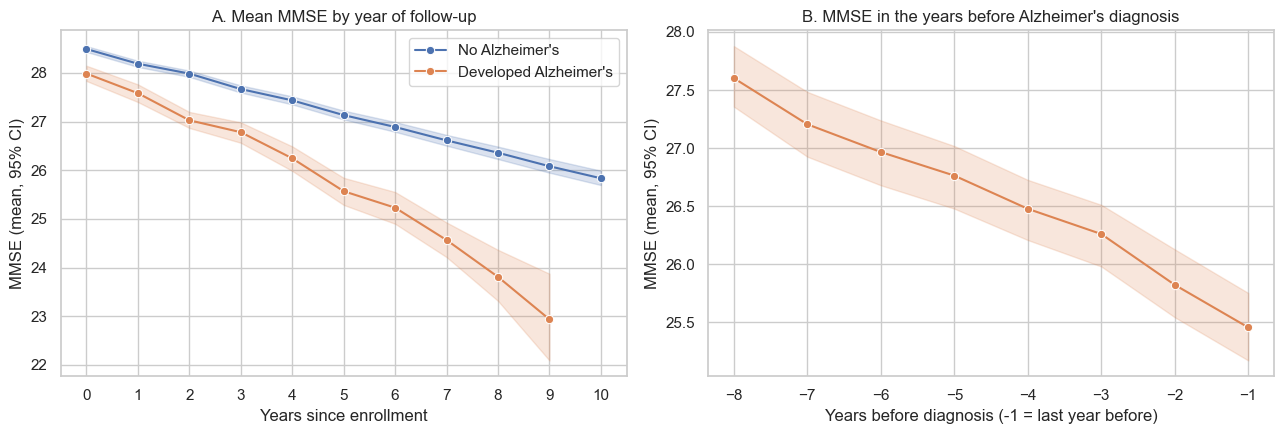

In [11]:
sns.set_theme(style="whitegrid")

# Label each patient's visits with their final outcome
group = (cohort.set_index("patient_id")["status"].eq("alzheimer")
         .map({True: "Developed Alzheimer's", False: "No Alzheimer's"}))
mmse_long = v.assign(group=v["patient_id"].map(group))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# A) Calendar of the study: years since enrollment
sns.lineplot(data=mmse_long, x="visit_year", y="mmse", hue="group",
             errorbar=("ci", 95), marker="o", ax=axes[0])
axes[0].set(title="A. Mean MMSE by year of follow-up",
            xlabel="Years since enrollment", ylabel="MMSE (mean, 95% CI)")
axes[0].set_xticks(range(11))
axes[0].legend(title=None)

# B) Clock of the disease: years before diagnosis
ad = cohort.loc[cohort["status"] == "alzheimer", ["patient_id", "event_date"]]
before = v.merge(ad, on="patient_id")
before["years_before_dx"] = np.floor(
    (before["visit_date"] - before["event_date"]).dt.days / 365.25).astype(int)

sns.lineplot(data=before[before["years_before_dx"] >= -8], x="years_before_dx", y="mmse",
             errorbar=("ci", 95), marker="o", color="C1", ax=axes[1])
axes[1].set(title="B. MMSE in the years before Alzheimer's diagnosis",
            xlabel="Years before diagnosis (-1 = last year before)", ylabel="MMSE (mean, 95% CI)")

plt.tight_layout()
plt.show()

## 8. Visualization – Risk factors at baseline

Proportion who developed Alzheimer's during follow-up, by APOE4 and age; baseline homocysteine by outcome.


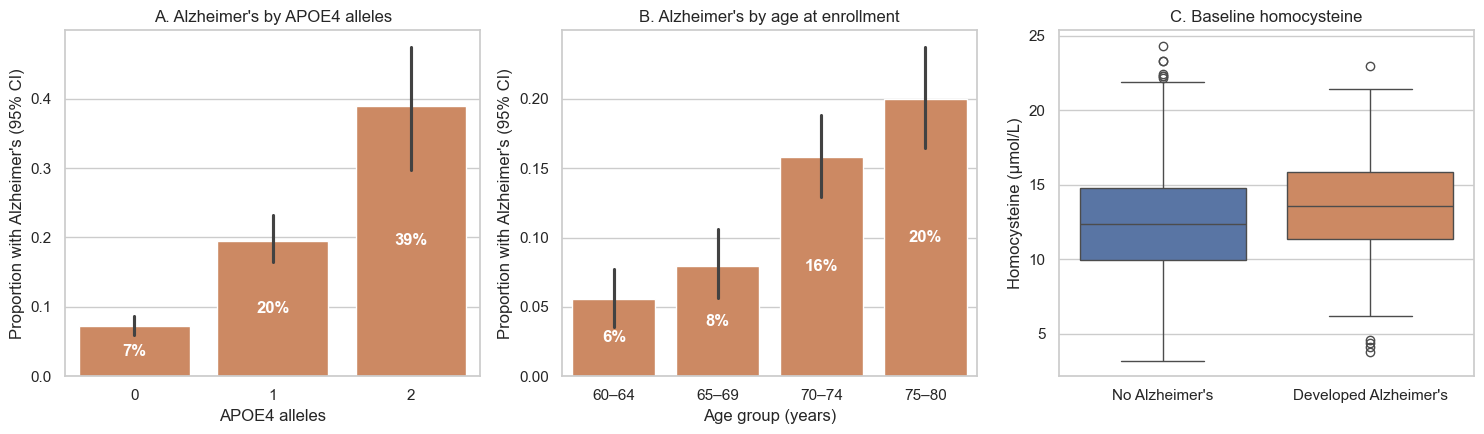

In [12]:
df_plot = cohort.assign(
    alzheimer=cohort["status"].eq("alzheimer").astype(int),
    age_group=pd.cut(cohort["age_baseline"], bins=[60, 65, 70, 75, 81], right=False,
                     labels=["60–64", "65–69", "70–74", "75–80"]),
    group=cohort["status"].eq("alzheimer").map(
        {True: "Developed Alzheimer's", False: "No Alzheimer's"}),
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# A) APOE4
sns.barplot(data=df_plot, x="apoe4_alleles", y="alzheimer",
            errorbar=("ci", 95), color="C1", ax=axes[0])
axes[0].set(title="A. Alzheimer's by APOE4 alleles", xlabel="APOE4 alleles",
            ylabel="Proportion with Alzheimer's (95% CI)")

# B) Age at enrollment
sns.barplot(data=df_plot, x="age_group", y="alzheimer",
            errorbar=("ci", 95), color="C1", ax=axes[1])
axes[1].set(title="B. Alzheimer's by age at enrollment", xlabel="Age group (years)",
            ylabel="Proportion with Alzheimer's (95% CI)")

# percentage labels inside the bars
for ax in axes[:2]:
    for bars in ax.containers:
        ax.bar_label(bars, fmt="{:.0%}", label_type="center",
                     color="white", fontweight="bold")

# C) Homocysteine
sns.boxplot(data=df_plot, x="group", y="homocysteine",
            hue="group", legend=False, ax=axes[2])
axes[2].set(title="C. Baseline homocysteine",
            xlabel="", ylabel="Homocysteine (µmol/L)")

plt.tight_layout()
plt.show()

### Interpretation – Risk factors at baseline

**Findings**

- **APOE4:** the proportion who developed Alzheimer's rises with each allele, from 7% (0 alleles) to 20% (1 allele) to 39% (2 alleles). Each allele roughly doubles the proportion, a clear dose-response.
- **Age at enrollment:** 6% (60–64), 8% (65–69), 16% (70–74), 20% (75–80). Risk rises with age.
- **Homocysteine:** higher in those who developed Alzheimer's (median 13.6 vs. 12.4 µmol/L), but the distributions overlap a lot, so the effect is modest.

**Reading the charts**

- The bars show the **mean of a 0/1 variable**, which is the proportion of patients with Alzheimer's in each group.
- The black lines are **95% confidence intervals**. The 2-allele APOE4 group has the widest interval because it is small (n = 118).
- Age groups use `right=False` (each range includes its left edge). The last limit is 81, so patients aged exactly 80.0 are included.

**Caveats**

1. **These are crude proportions.** They ignore patients who **died** or were **lost to follow-up** before they could develop Alzheimer's (competing risks and censoring).
2. **Risk at older ages is probably underestimated.** Older patients die more often, so fewer of them stay in follow-up long enough to be diagnosed.
3. **No adjustment for confounders.** Each chart looks at one factor at a time. Effects are mixed (for example, older patients with and without APOE4 are combined). The multivariable models in the next steps estimate each factor's effect **adjusting for the others**.
4. **Simulated data:** these associations were built into the simulation, so they confirm that the data behaves as designed. They are not new findings.


## 9. Visualization – Correlation between baseline variables

Spearman correlation (works for continuous and 0/1 variables, robust to skewed data).
Strongly correlated predictors carry overlapping information.


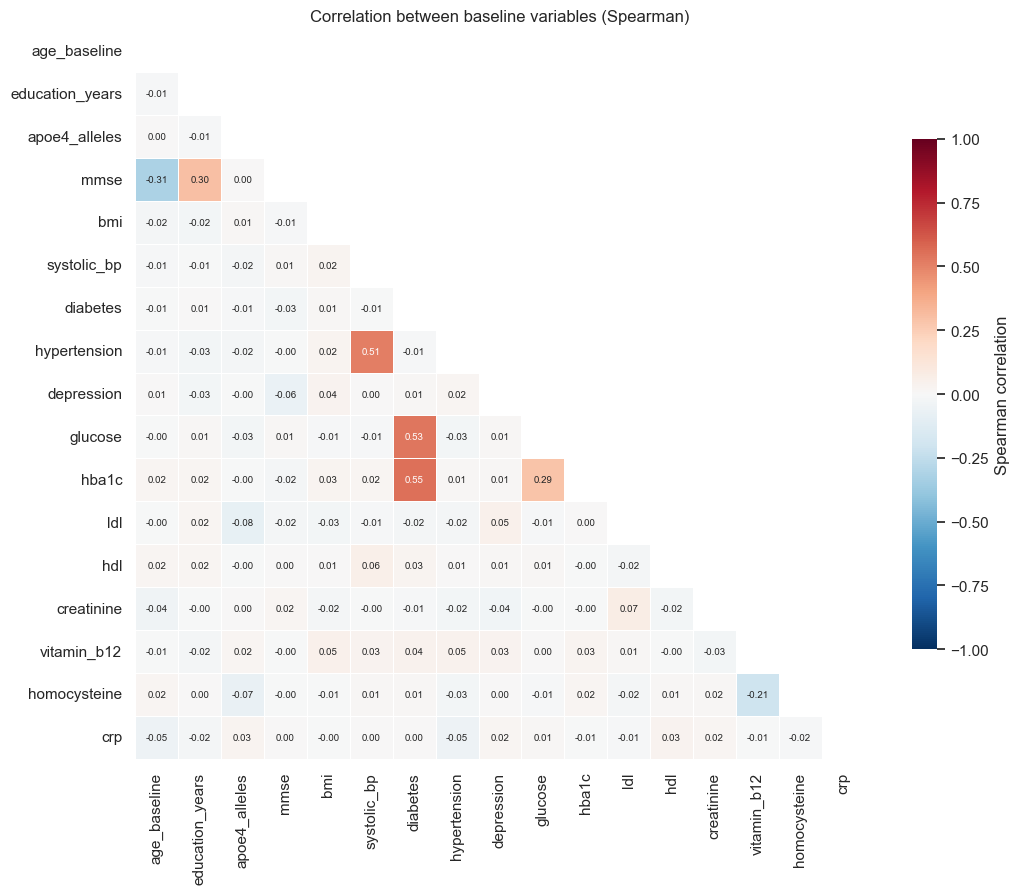

,variable_1,variable_2,rho
176,hba1c,diabetes,0.55
159,glucose,diabetes,0.53
124,hypertension,systolic_bp,0.51
51,mmse,age_baseline,-0.31
52,mmse,education_years,0.30
179,hba1c,glucose,0.29


In [13]:
FEATURES = ["age_baseline", "education_years", "apoe4_alleles", "mmse", "bmi", "systolic_bp",
            "diabetes", "hypertension", "depression",
            "glucose", "hba1c", "ldl", "hdl", "creatinine", "vitamin_b12", "homocysteine", "crp"]

corr = cohort[FEATURES].corr(method="spearman")
# hide the upper triangle (mirror image)
mask = np.triu(np.ones_like(corr, dtype=bool))

with sns.axes_style("white"):
    fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                annot=True, fmt=".2f", annot_kws={"size": 7}, square=True, linewidths=0.5,
                cbar_kws={"shrink": 0.7, "label": "Spearman correlation"}, ax=ax)
    ax.set_title("Correlation between baseline variables (Spearman)")
    plt.tight_layout()
    plt.show()

# Strongest pairs
pairs = corr.where(~mask).stack().rename("rho").reset_index()
pairs.columns = ["variable_1", "variable_2", "rho"]
pairs.reindex(pairs["rho"].abs().sort_values(
    ascending=False).index).head(6).round(2)

### Interpretation – Correlation between baseline variables

**Findings**

- Most pairs of variables are essentially uncorrelated (|rho| < 0.1).
- The strongest correlations are clinically expected:

| Pair                       | rho   | Explanation                            |
| -------------------------- | ----- | -------------------------------------- |
| HbA1c – diabetes           | 0.55  | Diabetes raises HbA1c                  |
| Glucose – diabetes         | 0.53  | Diabetes raises glucose                |
| Hypertension – systolic BP | 0.51  | Hypertension raises blood pressure     |
| MMSE – age                 | −0.31 | Older age, lower cognitive score       |
| MMSE – education           | 0.30  | More education, higher cognitive score |
| HbA1c – glucose            | 0.29  | Both reflect blood sugar               |
| Vitamin B12 – homocysteine | −0.21 | Low B12 raises homocysteine            |

**Implications for modeling**

1. **No serious multicollinearity.** All correlations are below 0.6, so every variable can enter the models.
2. **Overlapping information.** Diabetes, glucose and HbA1c tell a partly shared story, and so do hypertension and systolic BP. In logistic regression, the effect of diabetes may be **split** across these correlated variables, so individual coefficients should be read with care.
3. **Tree models** (XGBoost, LightGBM, CatBoost) are not affected by correlated predictors in the same way, but their feature importances can also be split between correlated variables.

**Method notes**

- **Spearman correlation** (rank-based): robust to skewed data and extreme values, and suitable for 0/1 variables.
- Only the lower triangle is shown, because the matrix is symmetric.
- This chart shows how predictors relate **to each other**, not to Alzheimer's. Associations with the outcome are in Table 1 and step 8.


## 10. Outcome definition and modeling cohort

**Outcome:** Alzheimer's diagnosis within **10 years** of enrollment (`alzheimer_10y` = 1).

| Group       | Definition                                                                                      |
| ----------- | ----------------------------------------------------------------------------------------------- |
| Case (1)    | Diagnosed with Alzheimer's during follow-up                                                     |
| Control (0) | Completed 10 years of follow-up without Alzheimer's                                             |
| Excluded    | Died or lost to follow-up before 10 years, without Alzheimer's → status at 10 years **unknown** |


In [14]:
HORIZON = 10  # years

ad_within = (cohort["status"] == "alzheimer") & (
    cohort["followup_years"] <= HORIZON)
ad_free_full = ~ad_within & ((cohort["followup_years"] >= HORIZON) | (
    cohort["status"] == "completed_10_years"))

cohort["outcome_group"] = "excluded (status unknown)"
cohort.loc[ad_within, "outcome_group"] = "case: Alzheimer's"
cohort.loc[ad_free_full, "outcome_group"] = "control: Alzheimer's-free"

# Who went where?
display(pd.crosstab(
    cohort["status"], cohort["outcome_group"], margins=True, margins_name="Total"))

# Modeling cohort: cases + controls only
model_df = cohort[cohort["outcome_group"]
                  != "excluded (status unknown)"].copy()
model_df["alzheimer_10y"] = (
    model_df["outcome_group"] == "case: Alzheimer's").astype(int)

print(f"Modeling cohort: {len(model_df)} patients | cases: {model_df['alzheimer_10y'].sum()} "
      f"({model_df['alzheimer_10y'].mean():.1%}) | excluded: {len(cohort) - len(model_df)}")

# Are the excluded patients different from the included ones?
cols = ["age_baseline", "apoe4_alleles", "mmse", "education_years", "diabetes"]
comp = (cohort.assign(included=cohort["outcome_group"] != "excluded (status unknown)")
              .groupby("included")[cols].mean().round(2))
comp.index = comp.index.map({True: "included", False: "excluded"})
comp

outcome_group,case: Alzheimer's,control: Alzheimer's-free,excluded (status unknown),Total
status,,,,
alzheimer,243,0,0,243
completed_10_years,0,898,0,898
death,0,0,389,389
lost_to_followup,0,0,470,470
Total,243,898,859,2000


Modeling cohort: 1141 patients | cases: 243 (21.3%) | excluded: 859


,age_baseline,apoe4_alleles,mmse,education_years,diabetes
included,,,,,
excluded,70.62,0.34,28.40,11.41,0.17
included,69.31,0.38,28.46,10.88,0.18


## 11. Predictors and train/test split

- **Predictors:** 19 baseline variables (demographics, genetics, clinical, labs)
- **Not used:** identifiers, dates, and anything describing follow-up or outcome (leakage)
- **Split:** 75% train / 25% test, stratified by outcome


In [15]:
from sklearn.model_selection import train_test_split

NUMERIC_FEATURES = ["age_baseline", "education_years", "apoe4_alleles", "mmse", "bmi", "systolic_bp",
                    "glucose", "hba1c", "ldl", "hdl", "creatinine", "vitamin_b12", "homocysteine", "crp"]
BINARY_FEATURES = ["diabetes", "hypertension", "depression"]
CATEGORICAL_FEATURES = ["sex", "smoking"]
FEATURES = NUMERIC_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES
TARGET = "alzheimer_10y"

# Safety check: nothing from the future can be a predictor
LEAKAGE = ["status", "event_date", "end_date",
           "followup_years", "outcome_group"]
assert not set(FEATURES) & set(LEAKAGE), "leakage column in FEATURES!"

X = model_df[FEATURES]
y = model_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

summary = pd.DataFrame({
    "patients": [len(y_train), len(y_test)],
    "cases": [y_train.sum(), y_test.sum()],
    "% cases": [f"{y_train.mean():.1%}", f"{y_test.mean():.1%}"],
}, index=["train", "test"])
display(summary)

print("Missing values in train (will be handled inside each model):")
X_train.isna().sum()[lambda s: s > 0]

,patients,cases,% cases
train,855,182,21.3%
test,286,61,21.3%


Missing values in train (will be handled inside each model):


glucose         67
hba1c           74
ldl             65
hdl             83
creatinine      77
vitamin_b12     83
homocysteine    60
crp             72
dtype: int64

### Notes – Predictors and train/test split

**Result**

|       | Patients | Cases | % cases |
| ----- | -------- | ----- | ------- |
| Train | 855      | 182   | 21.3%   |
| Test  | 286      | 61    | 21.3%   |

Missing lab values in the training set range from 60 (homocysteine) to 83 (HDL, vitamin B12) per test.

**1. Variables not used as predictors**

| Column                                                                | Reason                                                                                                                                              |
| --------------------------------------------------------------------- | --------------------------------------------------------------------------------------------------------------------------------------------------- |
| `patient_id`, `birth_date`, `enrollment_date`                         | Identifiers and dates, not patient characteristics (age is captured in `age_baseline`)                                                              |
| `status`, `event_date`, `end_date`, `followup_years`, `outcome_group` | **Describe the future** (data leakage). For example, `followup_years` is shorter for patients who developed Alzheimer's, so the model would "cheat" |
| `site`                                                                | Administrative, not biological. Could later be used to test the model at a site it has not seen                                                     |

The `assert` stops the code if a leakage column is accidentally added to `FEATURES`.

**2. Why split into train and test**

- The model **learns** from the training set (855 patients).
- The test set (286 patients) is **kept aside until the end** and represents new patients the model has never seen.
- Evaluating a model on the data it learned from overestimates its performance.

**3. `stratify=y`**
Keeps the same proportion of cases (21.3%) in both sets. With only 243 cases, a purely random split could leave too few cases in the test set.

**4. `random_state=42`**
Fixes the random shuffle, so the split, and therefore the results, are the same every time the notebook runs.

**5. Missing values are handled later, on purpose**
Imputation (filling missing values) must **learn only from the training set**. Using statistics from the full dataset (e.g., the overall median) would leak information from the test set into training. Imputation therefore goes inside a **pipeline**, together with each model (next step).


## 12. Model 1 – Logistic regression

- **Pipeline:** preprocessing + model in one object, so every step learns from the training data only
- **Evaluation:** 5-fold cross-validation on the training set (the test set is still locked)
- **Interpretation:** odds ratios (OR)


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

CONTINUOUS = [c for c in NUMERIC_FEATURES if c != "apoe4_alleles"]
# counts / 0-1 variables: keep their units
AS_IS = ["apoe4_alleles"] + BINARY_FEATURES

preprocess = ColumnTransformer([
    ("continuous", Pipeline([("impute", SimpleImputer(strategy="median")),
                             ("scale", StandardScaler())]), CONTINUOUS),
    ("as_is", "passthrough", AS_IS),
    ("categorical", OneHotEncoder(categories=[["F", "M"], ["never", "former", "current"]],
                                  drop="first"), CATEGORICAL_FEATURES),
], verbose_feature_names_out=False)

logreg = Pipeline([
    ("prep", preprocess),
    # C=inf -> no penalty (classic regression)
    ("model", LogisticRegression(C=np.inf, max_iter=1000)),
])

# Cross-validation on the training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc = cross_val_score(logreg, X_train, y_train, cv=cv, scoring="roc_auc")
print("CV AUC per fold:", auc.round(3),
      f"| mean {auc.mean():.3f} ± {auc.std():.3f}")

# Fit on the full training set and show odds ratios
logreg.fit(X_train, y_train)
coefs = pd.Series(logreg["model"].coef_[0],
                  index=logreg["prep"].get_feature_names_out())
odds_ratios = np.exp(coefs).sort_values(
    ascending=False).round(2).to_frame("OR")
odds_ratios["per"] = ["1 SD" if c in CONTINUOUS else "1 allele" if c == "apoe4_alleles"
                      else "vs reference" for c in odds_ratios.index]
odds_ratios

CV AUC per fold: [0.807 0.816 0.803 0.811 0.775] | mean 0.802 ± 0.014


,OR,per
apoe4_alleles,4.92,1 allele
diabetes,2.63,vs reference
age_baseline,2.36,1 SD
hypertension,1.70,vs reference
depression,1.68,vs reference
homocysteine,1.43,1 SD
sex_M,1.23,vs reference
vitamin_b12,1.15,1 SD
hdl,1.15,1 SD
ldl,1.09,1 SD


### Notes – Logistic regression: treatment of variables, pipeline, cross-validation and results

#### 1. Treatment of each variable

| Group        | Variables                                           | Missing values              | Transformation                 | OR interpreted as                       |
| ------------ | --------------------------------------------------- | --------------------------- | ------------------------------ | --------------------------------------- |
| Continuous   | age, education, MMSE, BMI, systolic BP, 8 lab tests | Median of the training data | Standardized (mean 0, SD 1)    | Change in odds **per 1 SD**             |
| Count        | APOE4 alleles (0, 1, 2)                             | None                        | Kept as is                     | Change in odds **per allele**           |
| Binary (0/1) | diabetes, hypertension, depression                  | None                        | Kept as is                     | **Yes vs. no**                          |
| Categorical  | sex, smoking                                        | None                        | One-hot encoding (0/1 columns) | **vs. reference**: female; never-smoker |

- **Standardizing** puts all continuous variables on the same scale, so their ORs can be compared with each other.
- **APOE4 and binary variables keep their natural units**, which makes their ORs easier to interpret clinically.
- **One-hot encoding** creates one column per category except the reference (`drop="first"`). The reference is set explicitly with `categories=`.

#### 2. Pipeline

`Pipeline` = **preprocessing + model** in a single object (`ColumnTransformer` → `LogisticRegression`).

- When the pipeline is fitted, the medians (imputation) and the means/SDs (scaling) are **learned from the training data only**.
- Inside cross-validation, they are **recalculated in every fold**, so no information from the validation fold leaks into training.
- The same object later applies the **same** transformations to the test set.

#### 3. Cross-validation (5-fold, stratified)

- The training set (855 patients) is split into 5 parts with the same proportion of cases.
- The model is trained on 4 parts and evaluated on the 5th; this rotates 5 times.
- It estimates performance **without touching the test set**, which stays locked until the final comparison of all models.

#### 4. Results

**Discrimination:** CV AUC = **0.80 ± 0.01** (folds: 0.81, 0.82, 0.80, 0.81, 0.78).
If we pick one random case and one random control, the model ranks the case as higher risk 80% of the time (0.5 = chance, 1.0 = perfect). The small variation between folds shows the estimate is stable.

**Odds ratios (adjusted for all other variables):**

| Variable                                                          | OR         | Per        | Interpretation             |
| ----------------------------------------------------------------- | ---------- | ---------- | -------------------------- |
| APOE4                                                             | 4.92       | allele     | Strongest risk factor      |
| Diabetes                                                          | 2.63       | yes vs. no | Risk factor                |
| Age                                                               | 2.36       | 1 SD       | Risk factor                |
| Hypertension                                                      | 1.70       | yes vs. no | Risk factor                |
| Depression                                                        | 1.68       | yes vs. no | Risk factor                |
| Homocysteine                                                      | 1.43       | 1 SD       | Risk factor                |
| Sex (male)                                                        | 1.23       | vs. female | Weak                       |
| Vitamin B12, HDL, LDL, CRP, systolic BP, BMI, creatinine, smoking | 0.96–1.15  |            | No relevant effect         |
| Glucose, HbA1c                                                    | 0.90, 0.87 | 1 SD       | See note below             |
| MMSE                                                              | 0.85       | 1 SD       | Higher score is protective |
| Education                                                         | 0.75       | 1 SD       | Protective                 |

- The model **recovered the risk factors built into the simulation** (APOE4, age, diabetes, hypertension, depression, homocysteine, MMSE, education), and variables with no simulated effect have OR ≈ 1. This confirms the pipeline works.
- **Glucose and HbA1c have OR < 1** even though diabetes is a risk factor. Once diabetes is in the model, glucose and HbA1c add little extra information. Because they are correlated with diabetes (rho ≈ 0.55, step 9), their coefficients become unstable. Individual ORs of correlated variables should not be over-interpreted.

#### 5. Limitations

- scikit-learn does not report **95% confidence intervals or p-values** for ORs. Use `statsmodels` for an inferential (epidemiological) table.
- Median imputation is simple; it ignores relationships between variables. Alternatives: multiple imputation, or adding a "value was missing" indicator.
- The AUC is from cross-validation on the training data. The final performance will be measured on the **test set** and compared with the other models.


## 13. Model 2 – XGBoost (gradient boosted trees)

- Builds many small decision trees in sequence; each new tree corrects the errors of the previous ones
- Handles missing values natively and needs no scaling
- Same 5-fold cross-validation on the training set as the logistic regression


CV AUC per fold: [0.799 0.772 0.793 0.799 0.766] | mean 0.786 ± 0.014


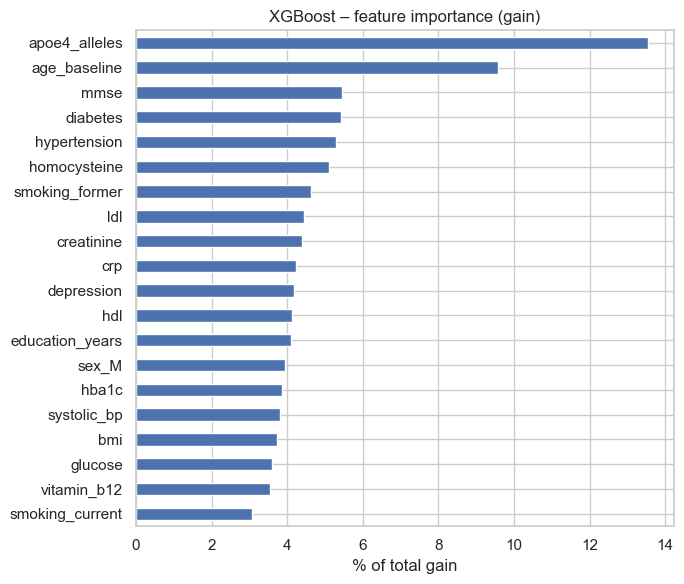

In [17]:
from xgboost import XGBClassifier

# Preprocessing for tree models: no imputation, no scaling; only one-hot for sex and smoking
tree_preprocess = ColumnTransformer([
    ("numeric", "passthrough", NUMERIC_FEATURES + BINARY_FEATURES),
    ("categorical", OneHotEncoder(categories=[["F", "M"], ["never", "former", "current"]],
                                  drop="first"), CATEGORICAL_FEATURES),
], verbose_feature_names_out=False)

xgb = Pipeline([
    ("prep", tree_preprocess),
    ("model", XGBClassifier(
        n_estimators=300,       # number of trees
        # how much each tree corrects (small = slower, more careful)
        learning_rate=0.03,
        # each tree asks at most 3 questions (limits complexity)
        max_depth=3,
        subsample=0.8,          # each tree sees a random 80% of patients
        colsample_bytree=0.8,   # ... and a random 80% of variables
        eval_metric="logloss",
        random_state=42,
        n_jobs=1,               # single thread -> identical results every run
    )),
])

# Same cross-validation as before (same folds: cv from step 12)
auc = cross_val_score(xgb, X_train, y_train, cv=cv, scoring="roc_auc")
print("CV AUC per fold:", auc.round(3),
      f"| mean {auc.mean():.3f} ± {auc.std():.3f}")

# Fit on the full training set and show feature importance
xgb.fit(X_train, y_train)
xgb_importance = pd.Series(xgb["model"].feature_importances_,
                           index=xgb["prep"].get_feature_names_out()).sort_values() * 100

fig, ax = plt.subplots(figsize=(7, 6))
xgb_importance.plot.barh(ax=ax, color="C0")
ax.set(title="XGBoost – feature importance (gain)", xlabel="% of total gain")
plt.tight_layout()
plt.show()

### Notes – XGBoost results

#### 1. How the model was set up

| Item             | Choice                                                                                    | Reason                                                                                  |
| ---------------- | ----------------------------------------------------------------------------------------- | --------------------------------------------------------------------------------------- |
| Missing values   | Not imputed                                                                               | XGBoost learns, at each split, which side to send patients with missing values to       |
| Scaling          | None                                                                                      | Trees split by thresholds (e.g., "age > 72?"), so the scale of a variable is irrelevant |
| Sex, smoking     | One-hot encoding (reference: female, never-smoker)                                        | Trees need numeric input                                                                |
| Hyperparameters  | 300 trees, learning rate 0.03, max depth 3, 80% of patients and 80% of variables per tree | Conservative settings to avoid **overfitting** with only 855 training patients          |
| Cross-validation | Same 5 folds as the logistic regression (`cv`)                                            | Fair comparison between models                                                          |
| Tuning           | Not done (fixed hyperparameters)                                                          | Possible later; usually gives small gains                                               |

#### 2. Discrimination

| Model               | CV AUC (mean ± SD) | Folds                        |
| ------------------- | ------------------ | ---------------------------- |
| Logistic regression | **0.802 ± 0.014**  | 0.81, 0.82, 0.80, 0.81, 0.78 |
| XGBoost             | **0.786 ± 0.014**  | 0.80, 0.77, 0.79, 0.80, 0.77 |

**XGBoost performed slightly worse than logistic regression.** This is expected here: the data were simulated with a **logistic, additive** risk formula (each factor adds to the risk, with no interactions or thresholds), which is exactly the structure logistic regression assumes. Tree-based models have an advantage when real relationships are **non-linear** or involve **interactions**.

> **Lesson:** a more complex model is not automatically better. In many clinical datasets, logistic regression performs as well as boosting models, and it is easier to interpret.

#### 3. Feature importance (gain)

| Variable         | % gain   |     | Variable          | % gain |
| ---------------- | -------- | --- | ----------------- | ------ |
| APOE4 alleles    | **13.6** |     | HDL               | 4.1    |
| Age              | **9.6**  |     | Education         | 4.1    |
| MMSE             | 5.4      |     | Sex (male)        | 3.9    |
| Diabetes         | 5.4      |     | HbA1c             | 3.9    |
| Hypertension     | 5.3      |     | Systolic BP       | 3.8    |
| Homocysteine     | 5.1      |     | BMI               | 3.7    |
| Smoking (former) | 4.6      |     | Glucose           | 3.6    |
| LDL              | 4.4      |     | Vitamin B12       | 3.5    |
| Creatinine       | 4.4      |     | Smoking (current) | 3.1    |
| CRP              | 4.2      |     |                   |        |
| Depression       | 4.2      |     |                   |        |

- **APOE4 and age** are the most important variables, consistent with the logistic regression.
- **Gain ≠ odds ratio:** importance shows how much a variable helped the trees separate cases from controls. It does **not** show the **direction** (risk vs. protection) or the **size** of the effect.
- **Variables with no simulated effect** (LDL, creatinine, CRP, smoking) still receive about 3–4.5%. Trees use noise variables for small, fine-tuning splits, so gain importance tends to **spread** across all variables and should not be over-interpreted.
- **Education ranks low (4.1%)** although it was a clear protective factor in the logistic regression (OR 0.75 per SD). Its effect is gradual and linear, which trees capture less efficiently than a regression coefficient.
- **SHAP values** (final step) will show direction and size of each variable's effect, for each patient.

#### 4. Limitations

- Results are from cross-validation on the training set; final performance will be measured on the **test set**.
- Hyperparameters were not tuned.
- Gain importance can be biased toward continuous variables with many possible split points.


## 14. Model 3 – LightGBM

- Gradient boosted trees like XGBoost, but faster (grows trees leaf-by-leaf and bins continuous values)
- Same preprocessing as XGBoost (`tree_preprocess`), same cross-validation folds


CV AUC per fold: [0.792 0.78  0.807 0.805 0.764] | mean 0.790 ± 0.016


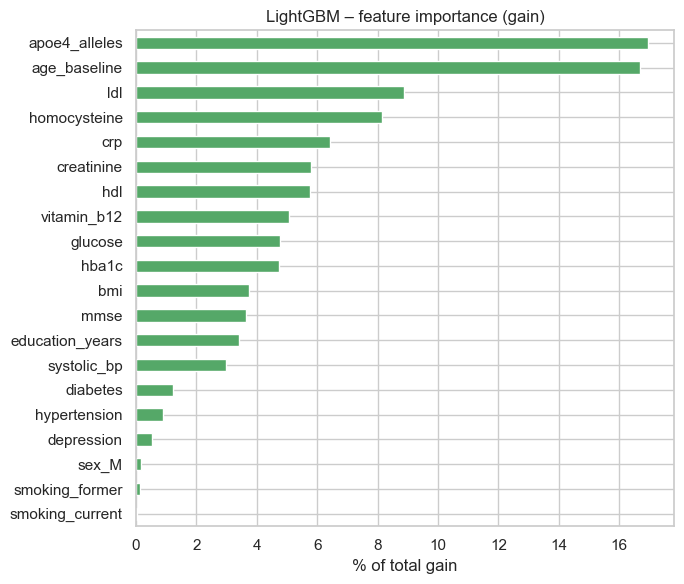

In [18]:
from lightgbm import LGBMClassifier

lgbm = Pipeline([
    ("prep", tree_preprocess),          # reused from step 13
    ("model", LGBMClassifier(
        n_estimators=300,
        learning_rate=0.03,
        # max leaves per tree (LightGBM's main complexity control)
        num_leaves=8,
        max_depth=3,               # same depth limit as XGBoost
        min_child_samples=20,      # each leaf needs at least 20 patients
        subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8,
        # same importance type as XGBoost (default would be "split")
        importance_type="gain",
        random_state=42,
        n_jobs=1,
        verbose=-1,                # silence LightGBM's training messages
    )),
])

auc = cross_val_score(lgbm, X_train, y_train, cv=cv, scoring="roc_auc")
print("CV AUC per fold:", auc.round(3),
      f"| mean {auc.mean():.3f} ± {auc.std():.3f}")

lgbm.fit(X_train, y_train)
lgbm_importance = pd.Series(lgbm["model"].feature_importances_,
                            index=lgbm["prep"].get_feature_names_out())
lgbm_importance = (lgbm_importance / lgbm_importance.sum() * 100).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
lgbm_importance.plot.barh(ax=ax, color="C2")
ax.set(title="LightGBM – feature importance (gain)", xlabel="% of total gain")
plt.tight_layout()
plt.show()

### Notes – LightGBM results and the limits of gain importance

#### 1. How the model was set up

| Item                    | Choice                                                                           | Reason                                                                                                                                       |
| ----------------------- | -------------------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------------------------- |
| Preprocessing           | `tree_preprocess` (same as XGBoost)                                              | Both tree models receive identical input                                                                                                     |
| Missing values, scaling | Not needed                                                                       | Same as XGBoost: native handling of `NaN`; trees split by thresholds                                                                         |
| Complexity              | `num_leaves=8`, `max_depth=3`, `min_child_samples=20`                            | LightGBM grows trees leaf-by-leaf, so it is controlled mainly by the number of leaves; 8 leaves ≈ a depth-3 tree, same complexity as XGBoost |
| Randomness              | 80% of patients (`subsample` + `subsample_freq=1`) and 80% of variables per tree | Reduces overfitting; `subsample_freq=1` is required for `subsample` to work                                                                  |
| Importance              | `importance_type="gain"`                                                         | Same metric as XGBoost (LightGBM's default, "split", only counts how often a variable is used)                                               |

#### 2. Discrimination

| Model               | CV AUC (mean ± SD) |
| ------------------- | ------------------ |
| Logistic regression | **0.802 ± 0.014**  |
| XGBoost             | 0.786 ± 0.014      |
| LightGBM            | 0.790 ± 0.016      |

- **LightGBM and XGBoost are practically tied.** Their difference (0.004) is much smaller than the variation between folds (±0.015).
- **Logistic regression is still slightly ahead**, because the data were simulated with a logistic, additive risk formula.

#### 3. Feature importance (gain): what it shows and what it does not

| Rank  | Variable         | % gain   | Real effect in the simulation |
| ----- | ---------------- | -------- | ----------------------------- |
| 1     | APOE4 alleles    | 17.0     | ✅ Strong risk factor         |
| 2     | Age              | 16.7     | ✅ Risk factor                |
| 3     | **LDL**          | **8.9**  | ❌ **None (noise)**           |
| 4     | Homocysteine     | 8.2      | ✅ Risk factor                |
| 5     | **CRP**          | **6.4**  | ❌ **None (noise)**           |
| 6–7   | Creatinine, HDL  | 5.8 each | ❌ None                       |
| …     | …                | …        | …                             |
| 15    | **Diabetes**     | **1.2**  | ✅ **Risk factor (OR 2.6)**   |
| 16    | **Hypertension** | **0.9**  | ✅ **Risk factor (OR 1.7)**   |
| 17    | **Depression**   | **0.5**  | ✅ **Risk factor (OR 1.7)**   |
| 18–20 | Sex, smoking     | ≈ 0      | ❌ None                       |

**Noise variables (LDL, CRP) rank above real risk factors (diabetes, hypertension, depression).**

**Why this happens:**

- **Gain** = total improvement in the model's fit from all splits that used a variable.
- A **continuous** variable (e.g., LDL, with hundreds of distinct values) offers **many possible thresholds** ("LDL > 118?", "LDL > 131?", …). The trees can always find one that improves the fit on the training data slightly, even **by chance**, and these small gains add up across 300 trees.
- A **binary** variable (e.g., diabetes, 0/1) offers **only one split**. Once used, it has nothing more to give, so its total gain stays low even when its real effect is large.
- Result: gain importance is **biased toward continuous variables** and against binary/categorical ones.

**XGBoost and LightGBM disagree beyond the top 2:**

| Variable | XGBoost gain | LightGBM gain |
| -------- | ------------ | ------------- |
| APOE4    | 13.6% (1st)  | 17.0% (1st)   |
| Age      | 9.6% (2nd)   | 16.7% (2nd)   |
| Diabetes | 5.4% (4th)   | 1.2% (15th)   |
| LDL      | 4.4% (8th)   | 8.9% (3rd)    |

Two models with almost the same AUC rank the variables very differently. Importance rankings depend on how each algorithm builds its trees, not only on the data.

#### 4. Take-home messages

1. **Gain importance measures how much a variable was used, not how much it truly matters.**
2. **Agreement across models is more trustworthy** than any single ranking: APOE4 and age are consistently at the top.
3. **Do not draw clinical conclusions from gain importance.** Use odds ratios (logistic regression) or **SHAP values** (final step), which show the direction and size of each effect and are less biased toward continuous variables.

#### 5. Limitations

- Cross-validation on the training set only; final performance will be measured on the **test set**.
- Hyperparameters were not tuned.


## 15. Model 4 – CatBoost

- Gradient boosted trees with **native handling of categorical variables** (no one-hot needed)
- Uses "symmetric" trees (same split at each level), which tend to overfit less on small data
- Receives the raw data directly: no preprocessing pipeline


CV AUC per fold: [0.796 0.795 0.799 0.807 0.783] | mean 0.796 ± 0.008


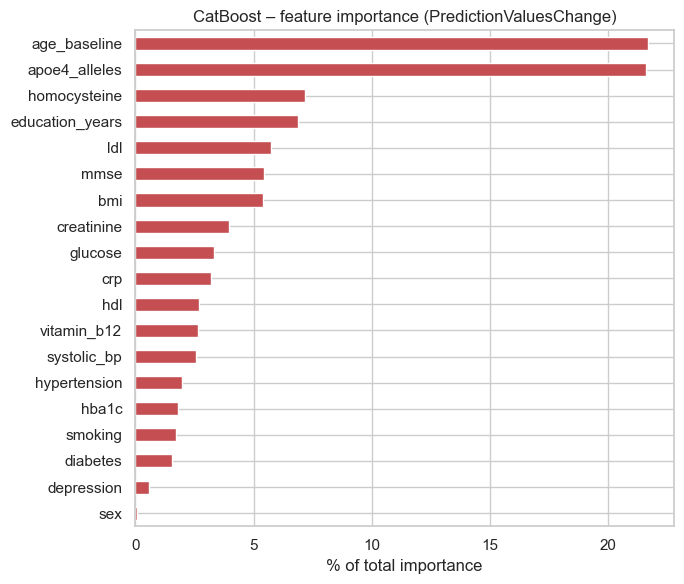

In [19]:
from catboost import CatBoostClassifier

cat = CatBoostClassifier(
    iterations=300,             # number of trees
    learning_rate=0.03,
    depth=3,                    # same complexity as XGBoost / LightGBM
    random_seed=42,
    verbose=0,                  # silence training messages
    allow_writing_files=False,  # don't create a "catboost_info" folder
)

# Categorical columns are passed at fit time (params= sends them to .fit inside cross-validation)
auc = cross_val_score(cat, X_train, y_train, cv=cv, scoring="roc_auc",
                      params={"cat_features": CATEGORICAL_FEATURES})
print("CV AUC per fold:", auc.round(3),
      f"| mean {auc.mean():.3f} ± {auc.std():.3f}")

cat.fit(X_train, y_train, cat_features=CATEGORICAL_FEATURES)
cat_importance = pd.Series(
    cat.get_feature_importance(), index=X_train.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
cat_importance.plot.barh(ax=ax, color="C3")
ax.set(title="CatBoost – feature importance (PredictionValuesChange)",
       xlabel="% of total importance")
plt.tight_layout()
plt.show()

### Notes – CatBoost results

#### 1. How the model was set up

| Item                  | Choice                                                 | Reason                                                                                                                                                         |
| --------------------- | ------------------------------------------------------ | -------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| Preprocessing         | **None** (raw `X_train`)                               | CatBoost handles missing values and categorical variables internally                                                                                           |
| Categorical variables | `sex`, `smoking` passed as `cat_features`              | Encoded internally with **ordered target statistics**: each category is replaced by outcome statistics computed only from "earlier" patients, to avoid leakage |
| Trees                 | Symmetric (oblivious), `depth=3`                       | The same split is used at every level; more rigid trees, which tend to overfit less on small datasets. Same depth as XGBoost/LightGBM                          |
| Other settings        | 300 trees, learning rate 0.03                          | Same as the other boosting models                                                                                                                              |
| Cross-validation      | Same 5 folds (`cv`); `cat_features` sent via `params=` | Passing `cat_features` in the constructor breaks `cross_val_score` (known CatBoost/scikit-learn incompatibility)                                               |

#### 2. Discrimination: all four models

| Model               | CV AUC (mean ± SD) |
| ------------------- | ------------------ |
| Logistic regression | **0.802** ± 0.014  |
| CatBoost            | 0.796 ± **0.008**  |
| LightGBM            | 0.790 ± 0.016      |
| XGBoost             | 0.786 ± 0.014      |

- **CatBoost is the best tree model and the most stable** (smallest variation between folds), consistent with symmetric trees being more robust on small data.
- **Logistic regression is still marginally ahead**, as expected for data simulated with a logistic, additive risk formula.
- **All four models are within 0.016 AUC of each other**, similar to the fold-to-fold variation. With 855 training patients, the differences are **not meaningful**. The final comparison on the test set will confirm.

#### 3. Feature importance (PredictionValuesChange)

| Variable                                        | CatBoost  | Real effect in the simulation |
| ----------------------------------------------- | --------- | ----------------------------- |
| Age                                             | **21.7%** | ✅ Risk factor                |
| APOE4 alleles                                   | **21.6%** | ✅ Strong risk factor         |
| Homocysteine                                    | 7.2%      | ✅ Risk factor                |
| Education                                       | 6.9%      | ✅ Protective                 |
| LDL                                             | 5.7%      | ❌ None                       |
| MMSE                                            | 5.4%      | ✅ Protective                 |
| BMI                                             | 5.4%      | ❌ None                       |
| Creatinine, glucose, CRP, HDL, B12, systolic BP | 2.6–4.0%  | ❌ None                       |
| Hypertension                                    | 2.0%      | ✅ Risk factor                |
| HbA1c, smoking                                  | 1.7–1.8%  | ❌ None                       |
| **Diabetes**                                    | **1.6%**  | ✅ **Risk factor (OR 2.6)**   |
| **Depression**                                  | **0.6%**  | ✅ **Risk factor (OR 1.7)**   |
| Sex                                             | 0.1%      | ❌ None                       |

- **PredictionValuesChange** = how much the model's predictions change, on average, when a variable is used in the trees. It is a different metric from gain, but it shares the same **bias toward continuous variables**: noise variables (LDL, BMI) rank above real binary risk factors (diabetes, depression).
- **Education (6.9%) is better captured** by CatBoost than by XGBoost (4.1%) and LightGBM (3.4%).

#### 4. Consistency across the three tree models

| Variable    | XGBoost | LightGBM | CatBoost |
| ----------- | ------- | -------- | -------- |
| APOE4       | 1st     | 1st      | 2nd      |
| Age         | 2nd     | 2nd      | 1st      |
| Diabetes    | 4th     | 15th     | 17th     |
| LDL (noise) | 8th     | 3rd      | 5th      |

- **Robust finding:** APOE4 and age are the top predictors in all three models (and the two largest effects in the logistic regression).
- **Unstable beyond the top 2:** rankings depend on the algorithm, so they should not be used to rank clinical risk factors.

#### 5. Limitations

- Cross-validation on the training set only; final performance will be measured on the **test set**.
- Hyperparameters were not tuned.
- Built-in importance metrics are biased and model-specific. **SHAP values** (final step) provide a consistent way to compare variables, with direction and size of effect.


## 16. Final evaluation on the test set (286 patients never seen by any model)

- **Discrimination:** ROC AUC (with 95% bootstrap CI) and precision–recall
- **Calibration:** do predicted risks match observed risks?
- **Overall accuracy of probabilities:** Brier score (lower = better)


,AUC,AUC 95% CI,Average precision,Brier score
model,,,,
Logistic regression,0.810,0.746–0.868,0.596,0.127
XGBoost,0.803,0.741–0.863,0.533,0.134
LightGBM,0.810,0.749–0.866,0.551,0.132
CatBoost,0.813,0.753–0.867,0.557,0.130


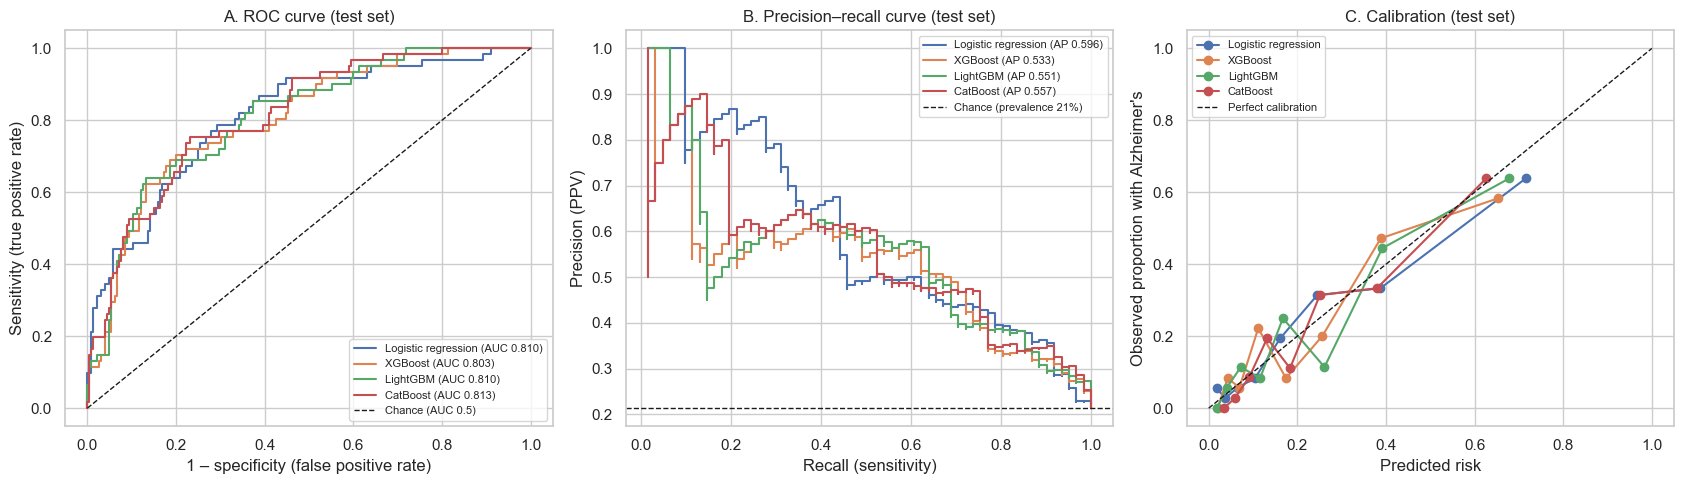

In [20]:
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve

models = {"Logistic regression": logreg,
          "XGBoost": xgb, "LightGBM": lgbm, "CatBoost": cat}

# Predicted risk (probability of Alzheimer's) for each test patient, from each model
pred = pd.DataFrame({name: m.predict_proba(X_test)[:, 1] for name, m in models.items()},
                    index=X_test.index)

# 95% CI for AUC by bootstrap (resample the test set 1,000 times)
rng = np.random.default_rng(42)
boot_idx = [rng.integers(0, len(y_test), len(y_test)) for _ in range(1000)]


def auc_ci(p):
    yt, pv = y_test.to_numpy(), p.to_numpy()
    aucs = [roc_auc_score(yt[i], pv[i]) for i in boot_idx]
    return np.percentile(aucs, [2.5, 97.5])


rows = []
for name in models:
    lo, hi = auc_ci(pred[name])
    rows.append({
        "model": name,
        "AUC": roc_auc_score(y_test, pred[name]),
        "AUC 95% CI": f"{lo:.3f}–{hi:.3f}",
        "Average precision": average_precision_score(y_test, pred[name]),
        "Brier score": brier_score_loss(y_test, pred[name]),
    })
results = pd.DataFrame(rows).set_index("model").round(3)
display(results)

# ----- Figures -----
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, pred[name])
    axes[0].plot(
        fpr, tpr, label=f"{name} (AUC {results.loc[name, 'AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, pred[name])
    # Step, not a line: a straight segment between two PR points implies
    # operating points that no threshold actually reaches, and it flatters the
    # curve. This is also scikit-learn's own default (drawstyle="steps-post").
    # The last pair sklearn appends is (recall 0, precision 1), an anchor with
    # no threshold behind it, so it is dropped with [:-1].
    axes[1].step(
        rec[:-1], prec[:-1], where="post",
        label=f"{name} (AP {results.loc[name, 'Average precision']:.3f})")
    frac_pos, mean_pred = calibration_curve(
        y_test, pred[name], n_bins=8, strategy="quantile")
    axes[2].plot(mean_pred, frac_pos, marker="o", label=name)

axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC 0.5)")
axes[0].set(title="A. ROC curve (test set)",
            xlabel="1 – specificity (false positive rate)", ylabel="Sensitivity (true positive rate)")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1,
                label=f"Chance (prevalence {y_test.mean():.0%})")
axes[1].set(title="B. Precision–recall curve (test set)",
            xlabel="Recall (sensitivity)", ylabel="Precision (PPV)")
axes[2].plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
axes[2].set(title="C. Calibration (test set)", xlabel="Predicted risk",
            ylabel="Observed proportion with Alzheimer's")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Notes – Final evaluation on the test set

#### 1. What was done

- The **test set** (286 patients: 61 cases, 225 controls) was used **once**, after all four models were trained and checked by cross-validation.
- Each model gave a **predicted probability** of Alzheimer's within 10 years for every test patient (`predict_proba`). All metrics use these probabilities, not yes/no predictions.
- **95% CI for AUC:** bootstrap with 1,000 resamples of the test set. The **same** resamples were used for all models, for a fair comparison.

#### 2. Results

| Model               | AUC (95% CI)            | Average precision | Brier score | CV AUC (train) |
| ------------------- | ----------------------- | ----------------- | ----------- | -------------- |
| Logistic regression | 0.810 (0.746–0.868)     | **0.596**         | **0.127**   | 0.802          |
| XGBoost             | 0.803 (0.741–0.863)     | 0.533             | 0.134       | 0.786          |
| LightGBM            | 0.810 (0.749–0.866)     | 0.551             | 0.132       | 0.790          |
| CatBoost            | **0.813** (0.753–0.867) | 0.557             | 0.130       | 0.796          |

#### 3. Interpretation

**A. Discrimination (ROC AUC): the four models are equivalent**

- All AUCs are between **0.80 and 0.81** (good discrimination; 0.5 = chance, 1.0 = perfect).
- The **confidence intervals overlap almost completely** (≈ 0.75–0.87). With only 61 cases in the test set, the uncertainty is larger than the differences between models, so **no model is significantly better**.
- **Test AUCs are close to the cross-validation AUCs**, so there is **no sign of overfitting**: the models perform on new patients as expected from training.

**B. Precision–recall: logistic regression is slightly ahead**

- **Average precision (AP)** summarizes the precision–recall curve. A random model would score the **prevalence (0.21)**. All models are well above it (0.53–0.60).
- **Precision (PPV)** answers the clinical question: _"Of the patients flagged as high risk, how many develop Alzheimer's?"_
- Logistic regression has the highest AP (0.596): it ranks the **highest-risk patients** slightly better.
- With a minority outcome (21%), the precision–recall curve is more informative than the ROC curve, which can look good even when many flagged patients are false positives.

**C. Calibration: predicted risks are reasonably reliable**

- Points close to the diagonal mean predicted risks match observed risks (e.g., patients predicted at ≈ 40% risk had ≈ 40% Alzheimer's).
- All models follow the diagonal reasonably well. The zig-zag is due to small groups (8 groups of ≈ 36 patients).
- **Brier score** (mean squared error of predicted probabilities; lower = better) combines discrimination and calibration. Logistic regression is best (0.127), but all models are close (0.127–0.134).

#### 4. Conclusion

- **All four models have equivalent discrimination** (AUC ≈ 0.81).
- **Logistic regression** is marginally better on average precision and Brier score, and it is the **simplest and most interpretable** model (odds ratios). On this data, it is the preferred model.
- This is consistent with how the data were simulated (a logistic, additive risk formula). On real data with non-linear effects or interactions, tree-based models may have an advantage, which is why comparing several models is good practice.

#### 5. Limitations

- **Small test set** (61 cases): wide confidence intervals.
- **No decision threshold chosen yet.** Sensitivity, specificity and PPV at a specific cut-off (e.g., "high risk if > 30%") depend on that choice, which must be made without tuning on the test set.
- **"Survivor" controls** (step 10): patients who died or were lost to follow-up were excluded, so real-world performance is likely somewhat lower. A survival / competing-risks model is planned to address this.
- **Simulated data:** results confirm that the pipeline works; they are not clinical findings.


## 17. Model explanation with SHAP (CatBoost, test set)

SHAP (SHapley Additive exPlanations) splits each patient's prediction into the contribution of each variable:
**prediction = average prediction + sum of the SHAP values of all variables**

- Global view: beeswarm plot (all test patients)
- Individual view: waterfall plot (the highest-risk patient)


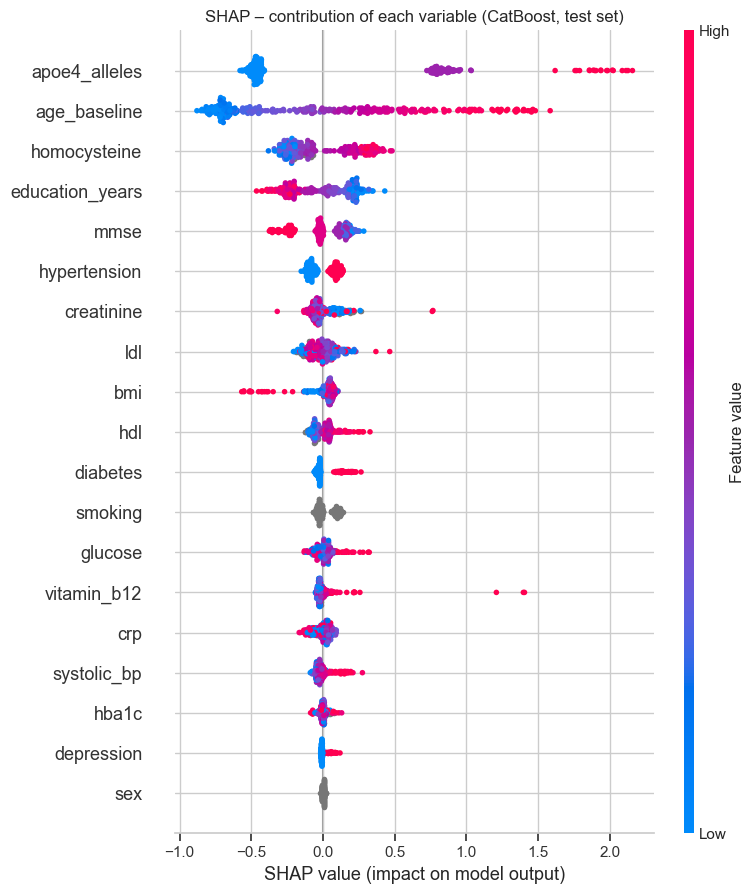

,mean |SHAP|
apoe4_alleles,0.664
age_baseline,0.577
homocysteine,0.218
education_years,0.195
mmse,0.140
hypertension,0.087
creatinine,0.074
ldl,0.072
bmi,0.068
hdl,0.057


Highest-risk test patient: predicted risk 90.2% | actually developed Alzheimer's: yes


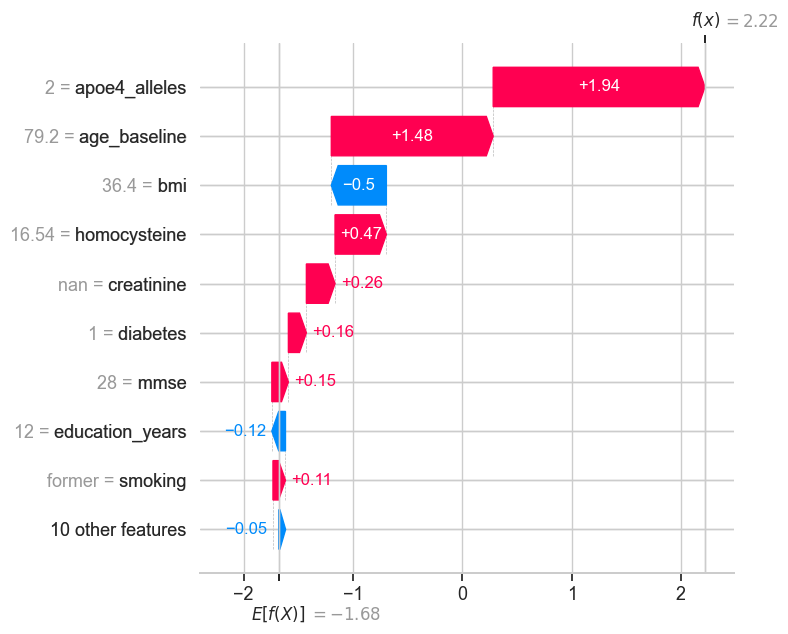

In [21]:
# SHAP values for every test patient (CatBoost; in log-odds units)
explainer = shap.TreeExplainer(cat)
shap_values = explainer(X_test)

# 1) Global: one dot per patient per variable
shap.plots.beeswarm(shap_values, max_display=19, show=False)
plt.title("SHAP – contribution of each variable (CatBoost, test set)")
plt.tight_layout()
plt.show()

# 2) Mean |SHAP| = average size of each variable's effect
shap_importance = (pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_test.columns)
                     .sort_values(ascending=False).round(3))
display(shap_importance.to_frame("mean |SHAP|"))

# 3) Individual: the patient with the highest predicted risk
risk = cat.predict_proba(X_test)[:, 1]
i = int(np.argmax(risk))
print(f"Highest-risk test patient: predicted risk {risk[i]:.1%} | "
      f"actually developed Alzheimer's: {'yes' if y_test.iloc[i] == 1 else 'no'}")
shap.plots.waterfall(shap_values[i], max_display=10, show=False)
plt.tight_layout()
plt.show()

### Notes – SHAP results (CatBoost, test set)

#### 1. What SHAP values are

- For each patient, SHAP splits the model's prediction into **one contribution per variable**:
  **prediction = average prediction + sum of SHAP values**
- **Positive** SHAP value → the variable **raises** that patient's risk; **negative** → **lowers** it.
- Units are **log-odds** (the same scale as logistic regression coefficients). Conversion to probability: p = 1 / (1 + e^(−log-odds)).
- `TreeExplainer` computes **exact** SHAP values for tree models.

#### 2. Global results (all 286 test patients)

| Rank  | Variable                                | Mean \|SHAP\| | Direction                                          | Real effect in the simulation |
| ----- | --------------------------------------- | ------------- | -------------------------------------------------- | ----------------------------- |
| 1     | APOE4 alleles                           | **0.664**     | More alleles → ↑ risk (3 distinct groups: 0, 1, 2) | ✅ Strong risk factor         |
| 2     | Age                                     | **0.577**     | Older → ↑ risk (smooth gradient)                   | ✅ Risk factor                |
| 3     | Homocysteine                            | 0.218         | Higher → ↑ risk                                    | ✅ Risk factor                |
| 4     | Education                               | 0.195         | More years → ↓ risk                                | ✅ Protective                 |
| 5     | MMSE                                    | 0.140         | Higher score → ↓ risk                              | ✅ Protective                 |
| 6     | Hypertension                            | 0.087         | Yes → ↑ risk                                       | ✅ Risk factor                |
| 7–10  | Creatinine, LDL, BMI, HDL               | 0.057–0.074   | No consistent pattern                              | ❌ None                       |
| 11    | Diabetes                                | 0.054         | Yes → ↑ risk                                       | ✅ Risk factor                |
| 12–16 | Smoking, glucose, B12, CRP, systolic BP | 0.042–0.052   | No consistent pattern                              | ❌ None                       |
| 17    | HbA1c                                   | 0.017         | —                                                  | ❌ None                       |
| 18    | Depression                              | 0.014         | Yes → ↑ risk                                       | ✅ Risk factor                |
| 19    | Sex                                     | 0.005         | —                                                  | ❌ None                       |

**Main findings**

- **The top 6 variables are all real effects**, with the **correct direction**, matching the logistic regression odds ratios. Gain importance (steps 13–15) could not show direction and ranked noise variables (e.g., LDL) much higher.
- **APOE4 shows a clear dose-response**: three separate clusters of dots for 0, 1 and 2 alleles.
- **Noise variables** (creatinine, LDL, BMI, HDL, CRP…) have SHAP values scattered around zero with no consistent color pattern, plus a few isolated extreme dots. This is the typical signature of a variable without a real effect.
- **Diabetes and depression remain underestimated** (real ORs 2.6 and 1.7, but low mean |SHAP|). Part of the diabetes signal is absorbed by correlated variables (glucose, HbA1c), and binary variables only affect the minority of patients who have the condition, which lowers their _average_ contribution.
- **Gray dots (sex, smoking):** text variables have no "high/low" value to color.

#### 3. Individual explanation: highest-risk test patient

|                                | Value                                              |
| ------------------------------ | -------------------------------------------------- |
| Predicted risk                 | **90.2%** (log-odds 2.22)                          |
| Actually developed Alzheimer's | **Yes**                                            |
| Starting point, E[f(X)]        | −1.68 log-odds (≈ 16%), the model's average output |

| Variable (value)           | SHAP      | Comment                                              |
| -------------------------- | --------- | ---------------------------------------------------- |
| APOE4 = 2 alleles          | **+1.94** | Largest contribution                                 |
| Age = 79.2 years           | **+1.48** | Near the top of the age range                        |
| BMI = 36.4                 | **−0.50** | ⚠️ **Spurious**: BMI has no effect in the simulation |
| Homocysteine = 16.5 µmol/L | +0.47     | High value                                           |
| Creatinine = missing       | +0.26     | ⚠️ The model assigns meaning to a **missing test**   |
| Diabetes = yes             | +0.16     |                                                      |
| MMSE = 28                  | +0.15     | Slightly below the cohort median (29)                |
| Education = 12 years       | −0.12     | Slightly above the median (11)                       |
| Smoking = former           | +0.11     | ⚠️ Smoking has no effect in the simulation           |
| 10 other variables         | −0.05     |                                                      |

#### 4. Lessons

1. **SHAP explains what the model does, not what causes the disease.** When a model learns noise (e.g., "very high BMI is protective"), SHAP faithfully shows that noise. This makes it a good tool for **detecting spurious patterns**.
2. **Missing values can carry signal.** Tree models treat "missing" as information. In real data this can reflect something real (e.g., sicker patients have more tests ordered); here it is chance.
3. **Mean |SHAP| is the most reliable ranking** among the importance measures used, and it agrees with the logistic regression on the main risk factors.
4. **Robust conclusion across all methods** (odds ratios, gain, SHAP): **APOE4 and age** are the strongest predictors, followed by homocysteine, education and MMSE.

#### 5. Limitations

- SHAP values describe **associations learned by the model**, not causal effects.
- With correlated predictors (diabetes, glucose, HbA1c), credit can be **split** between variables, so individual values should be read with care.
- Computed on the test set (286 patients); patterns for rare values (e.g., very high BMI, 2 APOE4 alleles) rest on few patients.
- Simulated data: results validate the pipeline; they are not clinical findings.


# Part 2 – Survival analysis

Uses **all 2,000 patients** and their follow-up time, instead of excluding those who died or were lost to follow-up.


## 18. Survival dataset (all 2,000 patients)

Each patient contributes:

- **time**: years from enrollment to the end of their follow-up
- **event**: how follow-up ended → 0 = censored (completed 10 years or lost), 1 = Alzheimer's, 2 = death (competing event)


In [22]:
EVENT_CODE = {"completed_10_years": 0,
              "lost_to_followup": 0, "alzheimer": 1, "death": 2}
EVENT_LABEL = {0: "censored", 1: "alzheimer", 2: "death"}

surv = cohort.copy()
surv["event"] = surv["status"].map(EVENT_CODE)
surv["time_years"] = surv["followup_years"]

assert surv["event"].notna().all() and (surv["time_years"] > 0).all()

summary = (surv.assign(event_label=surv["event"].map(EVENT_LABEL))
               .groupby("event_label")
               .agg(patients=("patient_id", "size"),
                    median_years=("time_years", "median"),
                    person_years=("time_years", "sum"))
               .round(1))
display(summary)

person_years = surv["time_years"].sum()
n_ad = (surv["event"] == 1).sum()
print(
    f"Total follow-up: {person_years:,.0f} person-years | median {surv['time_years'].median():.1f} years")
print(f"Alzheimer's incidence rate: {n_ad} cases / {person_years:,.0f} person-years "
      f"= {n_ad / person_years * 1000:.1f} per 1,000 person-years")

,patients,median_years,person_years
event_label,,,
alzheimer,243,5.9,1394.4
censored,1368,10.0,11022.6
death,389,5.1,1945.8


Total follow-up: 14,363 person-years | median 9.1 years
Alzheimer's incidence rate: 243 cases / 14,363 person-years = 16.9 per 1,000 person-years


### Notes – Survival dataset

#### 1. Event coding

| Code | Meaning                             | Patients  | Includes                                           |
| ---- | ----------------------------------- | --------- | -------------------------------------------------- |
| 0    | **Censored**                        | 1,368     | Completed 10 years (898) + lost to follow-up (470) |
| 1    | **Alzheimer's** (event of interest) | 243       |                                                    |
| 2    | **Death** (competing event)         | 389       |                                                    |
|      | **Total**                           | **2,000** | **Nobody is excluded**                             |

**Time** = years from enrollment to the end of follow-up (Alzheimer's diagnosis, death, loss to follow-up, or last visit at year 10).

#### 2. Results

| Event       | Patients  | Median follow-up (years) | Person-years |
| ----------- | --------- | ------------------------ | ------------ |
| Alzheimer's | 243       | 5.9                      | 1,394.4      |
| Censored    | 1,368     | 10.0                     | 11,022.6     |
| Death       | 389       | 5.1                      | 1,945.8      |
| **Total**   | **2,000** | **9.1**                  | **14,363**   |

**Incidence rate of Alzheimer's: 243 / 14,363 person-years = 16.9 per 1,000 person-years** (≈ 1.7% of at-risk patients per year).

#### 3. Key concepts

**Censoring**

- A censored patient was **Alzheimer's-free up to their last follow-up time**; after that, their status is unknown.
- A patient lost at year 4 contributes **4 years** of information. In the logistic regression (step 10), patients like this were **excluded** (859 patients, 43%). Here, they all contribute.
- **Assumption, non-informative censoring:** patients who were censored had the same risk as those who remained under follow-up. This holds in the simulation (loss to follow-up was random), but must be questioned in real studies, where people who drop out are often sicker or healthier.

**Death as a competing event**

- A patient who died can **never** develop Alzheimer's afterwards, unlike a patient lost to follow-up, who might develop it outside our view.
- Treating death as ordinary censoring assumes the deceased "could still develop Alzheimer's", which **overestimates** the probability of Alzheimer's. This is why death is coded separately (2).

**Person-years and incidence rate**

- **Person-years** sum the follow-up time of all patients (1 patient × 10 years = 10 patients × 1 year).
- The **incidence rate** (cases / person-years) uses all patients and accounts for different lengths of follow-up.
- A simple proportion (243 / 2,000 = 12%) ignores follow-up time and underestimates the risk, because many patients were not observed for the full 10 years.

#### 4. Note on follow-up time

- For patients lost to follow-up, time ends at the recorded date of loss (`event_date`). A more conservative choice is the **last visit** attended, since Alzheimer's-free status is only confirmed at visits. With annual visits, the difference is less than one year per patient.


## 19. Cumulative incidence of Alzheimer's (death as a competing risk)

- **Cumulative incidence (Aalen–Johansen):** probability of developing Alzheimer's by time _t_, accounting for patients who died first
- **Naive 1 − Kaplan–Meier:** treats death as ordinary censoring → overestimates the risk (shown for comparison)


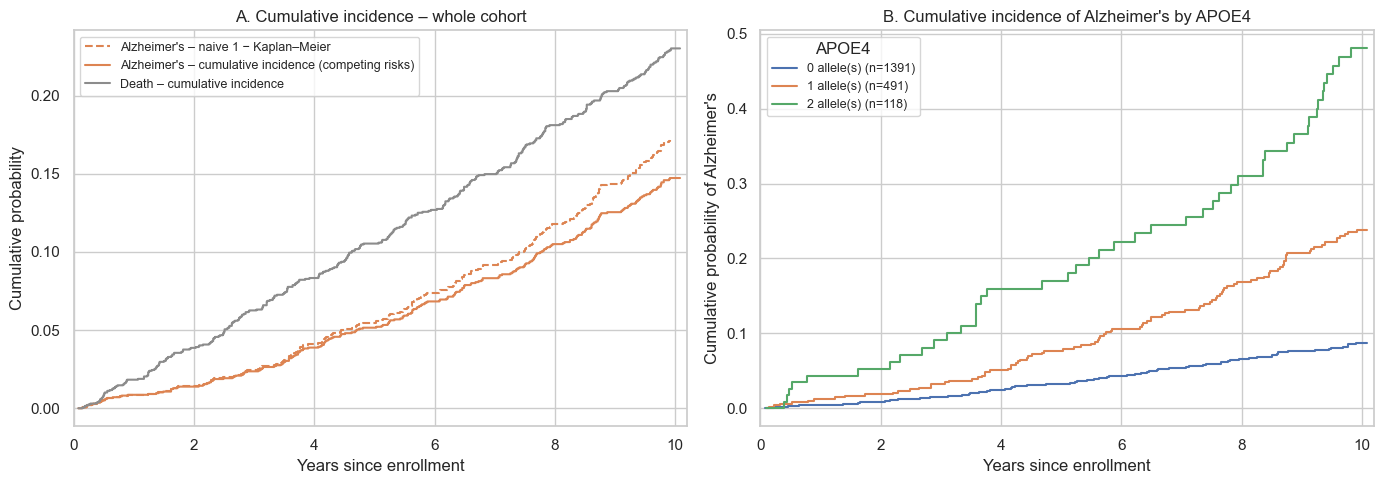

10-year cumulative incidence of death: 23.0%


,n,cumulative incidence,naive 1 − KM,overestimation
APOE4 alleles,,,,
all,2000,0.147,0.172,0.025
0,1391,0.087,0.101,0.014
1,491,0.238,0.280,0.042
2,118,0.481,0.576,0.095


In [23]:
from statsmodels.duration.survfunc import SurvfuncRight, CumIncidenceRight


def cumulative_incidence(df):
    """Aalen–Johansen cumulative incidence of Alzheimer's (1) and death (2)."""
    ci = CumIncidenceRight(df["time_years"], df["event"])
    return pd.DataFrame({"time": ci.times, "alzheimer": ci.cinc[0], "death": ci.cinc[1]})


def naive_km(df):
    """1 − Kaplan–Meier for Alzheimer's, treating death as ordinary censoring (biased)."""
    km = SurvfuncRight(df["time_years"], (df["event"] == 1).astype(int))
    return pd.DataFrame({"time": km.surv_times, "alzheimer": 1 - km.surv_prob})


def at(curve, t, col="alzheimer"):
    """Value of a step curve at time t."""
    return curve.loc[curve["time"] <= t, col].iloc[-1]


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# A) Whole cohort: correct vs naive
ci_all, km_all = cumulative_incidence(surv), naive_km(surv)
axes[0].step(km_all["time"], km_all["alzheimer"], where="post", ls="--", color="C1",
             label="Alzheimer's – naive 1 − Kaplan–Meier")
axes[0].step(ci_all["time"], ci_all["alzheimer"], where="post", color="C1",
             label="Alzheimer's – cumulative incidence (competing risks)")
axes[0].step(ci_all["time"], ci_all["death"], where="post", color="C7",
             label="Death – cumulative incidence")
axes[0].set(title="A. Cumulative incidence – whole cohort", xlabel="Years since enrollment",
            ylabel="Cumulative probability", xlim=(0, 10.2))
axes[0].legend(fontsize=9)

# B) By APOE4
rows = [{"APOE4 alleles": "all", "n": len(surv),
         "cumulative incidence": at(ci_all, 10), "naive 1 − KM": at(km_all, 10)}]
for k, g in surv.groupby("apoe4_alleles"):
    c, kmg = cumulative_incidence(g), naive_km(g)
    axes[1].step(c["time"], c["alzheimer"], where="post",
                 label=f"{k} allele(s) (n={len(g)})")
    rows.append({"APOE4 alleles": k, "n": len(g),
                 "cumulative incidence": at(c, 10), "naive 1 − KM": at(kmg, 10)})
axes[1].set(title="B. Cumulative incidence of Alzheimer's by APOE4", xlabel="Years since enrollment",
            ylabel="Cumulative probability of Alzheimer's", xlim=(0, 10.2))
axes[1].legend(title="APOE4", fontsize=9)
plt.tight_layout()
plt.show()

# 10-year risk table
risk10 = pd.DataFrame(rows).set_index("APOE4 alleles")
risk10["overestimation"] = risk10["naive 1 − KM"] - \
    risk10["cumulative incidence"]
print(f"10-year cumulative incidence of death: {at(ci_all, 10, 'death'):.1%}")
risk10.round(3)

### Notes – Cumulative incidence with competing risks

#### 1. Methods compared

| Method                                    | How death is treated                                                            | What it estimates                                                                       |
| ----------------------------------------- | ------------------------------------------------------------------------------- | --------------------------------------------------------------------------------------- |
| **Cumulative incidence (Aalen–Johansen)** | **Competing event**: a patient who dies can no longer develop Alzheimer's       | The real-world probability of being diagnosed with Alzheimer's by time _t_              |
| Naive 1 − Kaplan–Meier                    | Ordinary censoring: assumes patients who died "could still develop Alzheimer's" | A hypothetical risk in a world where nobody dies, which **overestimates** the real risk |

#### 2. Results at 10 years

**Whole cohort**

- Cumulative incidence of **Alzheimer's: 14.7%**
- Cumulative incidence of **death: 23.0%** (death was more frequent than Alzheimer's)

**By APOE4**

| APOE4 alleles | n     | Cumulative incidence | Naive 1 − KM | Overestimation  |
| ------------- | ----- | -------------------- | ------------ | --------------- |
| All           | 2,000 | **14.7%**            | 17.2%        | +2.5 points     |
| 0             | 1,391 | **8.7%**             | 10.1%        | +1.4 points     |
| 1             | 491   | **23.8%**            | 28.0%        | +4.2 points     |
| 2             | 118   | **48.1%**            | 57.6%        | **+9.5 points** |

#### 3. Interpretation

**A. The naive Kaplan–Meier overestimates the risk of Alzheimer's**

- In panel A, the dashed curve (naive) separates from the solid curve (correct) over time, as deaths accumulate.
- The overestimation is **largest in the highest-risk group** (2 APOE4 alleles: 57.6% vs 48.1%). The more frequent both events are, the more they compete for the same patients.
- **Rule:** when a competing event (here, death) is common, use cumulative incidence, not 1 − Kaplan–Meier.

**B. Strong, sustained effect of APOE4 over time**

- The curves separate early and keep diverging over the 10 years.
- With **2 alleles, almost 1 in 2** patients develops Alzheimer's within 10 years; with **0 alleles, fewer than 1 in 10**.
- The 2-allele curve has large steps because the group is small (118 patients): each new case moves the curve noticeably, so this estimate is the least precise.

**C. Comparison with earlier estimates of the 10-year risk**

| Method                                     | 10-year risk | Why it is biased                                                                                 |
| ------------------------------------------ | ------------ | ------------------------------------------------------------------------------------------------ |
| Simple proportion (243 / 2,000)            | 12.2%        | **Underestimates:** counts patients lost or deceased early as "no Alzheimer's"                   |
| Logistic regression cohort (243 / 1,141)   | 21.3%        | **Overestimates:** excludes patients who died or were lost, keeping only "survivors" as controls |
| Naive 1 − Kaplan–Meier                     | 17.2%        | **Overestimates:** ignores that patients who died cannot develop Alzheimer's                     |
| **Cumulative incidence (competing risks)** | **14.7%**    | Uses all patients and their follow-up time, and handles death correctly                          |

> The 21.3% "prevalence" in the logistic regression cohort is **not** the real 10-year risk. Predicted probabilities from those models are inflated relative to the full cohort, which matters if they are used to communicate risk to patients.

#### 4. Limitations

- **Unadjusted:** the APOE4 curves do not account for differences in age or other factors between groups. The Cox model (next step) adjusts for all variables at once.
- **Non-informative censoring assumed** for patients lost to follow-up (true in the simulation, to be questioned in real data).
- **Confidence intervals** are not shown in the figure. `CumIncidenceRight` provides standard errors (`cinc_se`) that can be used to compute them.
- Simulated data: results validate the method; they are not clinical findings.


## 20. Cox proportional hazards model – Alzheimer's (cause-specific)

- **All 2,000 patients**, using their follow-up time
- Event = Alzheimer's; death and loss to follow-up are censored at their time (**cause-specific hazard**)
- Same predictors and coding as the logistic regression → hazard ratios (HR) comparable with odds ratios (OR)


In [24]:
from statsmodels.duration.hazard_regression import PHReg

# Same coding as the logistic regression (step 12):
# continuous → median-imputed and standardized (HR per 1 SD); APOE4 per allele; binary yes/no;
# sex and smoking as 0/1 columns vs reference (female, never-smoker)
CONTINUOUS = [c for c in NUMERIC_FEATURES if c != "apoe4_alleles"]
Xs = surv[CONTINUOUS].fillna(surv[CONTINUOUS].median())
Xs = (Xs - Xs.mean()) / Xs.std()

design = pd.concat([
    Xs,
    surv[["apoe4_alleles"] + BINARY_FEATURES],
    (surv["sex"] == "M").astype(int).rename("sex_M"),
    (surv["smoking"] == "former").astype(int).rename("smoking_former"),
    (surv["smoking"] == "current").astype(int).rename("smoking_current"),
], axis=1).astype(float)

cox = PHReg(surv["time_years"], design,
            # 1 = Alzheimer's; everything else censored
            status=(surv["event"] == 1).astype(int),
            ties="efron").fit()

ci = np.exp(cox.conf_int())
hazard_ratios = pd.DataFrame({
    "HR": np.exp(cox.params),
    "95% CI low": ci[:, 0],
    "95% CI high": ci[:, 1],
    "p-value": cox.pvalues,
}, index=design.columns)
hazard_ratios["OR (logistic, step 12)"] = odds_ratios["OR"].reindex(
    hazard_ratios.index)

display(cox.summary().tables[0])
hazard_ratios.sort_values("HR", ascending=False).round(3)

,0,1,2,3
0,Model:,PH Reg,Sample size:,1997
1,Dependent variable:,time_years,Num. events:,243
2,Ties:,Efron,,


,HR,95% CI low,95% CI high,p-value,"OR (logistic, step 12)"
apoe4_alleles,3.103,2.614,3.685,0.000,4.92
diabetes,2.116,1.354,3.306,0.001,2.63
age_baseline,1.972,1.703,2.283,0.000,2.36
hypertension,1.518,1.127,2.045,0.006,1.70
depression,1.513,1.069,2.141,0.020,1.68
homocysteine,1.353,1.182,1.550,0.000,1.43
vitamin_b12,1.180,1.033,1.348,0.014,1.15
sex_M,1.069,0.828,1.379,0.611,1.23
systolic_bp,1.065,0.914,1.241,0.421,1.03
ldl,1.064,0.935,1.211,0.345,1.09


### Notes – Cox model (cause-specific) for Alzheimer's

#### 1. Model setup

| Item       | Choice                                                                                                                                                                |
| ---------- | --------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| Patients   | All 2,000 (1,997 contribute; 3 were lost to follow-up before the first Alzheimer's case occurred, so they are never "at risk" at any event time)                      |
| Events     | 243 Alzheimer's diagnoses                                                                                                                                             |
| Censoring  | Death, loss to follow-up and end of study (10 years) are censored **at their time** → **cause-specific hazard**                                                       |
| Predictors | Same 19 variables and coding as the logistic regression: continuous per 1 SD (median-imputed); APOE4 per allele; binary yes vs. no; sex vs. female; smoking vs. never |
| Ties       | Efron method                                                                                                                                                          |

#### 2. Results

| Variable              | HR       | 95% CI    | p-value   | OR (logistic) | Real effect in the simulation |
| --------------------- | -------- | --------- | --------- | ------------- | ----------------------------- |
| APOE4 (per allele)    | **3.10** | 2.61–3.69 | <0.001    | 4.92          | ✅ Risk factor                |
| Diabetes              | **2.12** | 1.35–3.31 | 0.001     | 2.63          | ✅ Risk factor                |
| Age (per SD)          | **1.97** | 1.70–2.28 | <0.001    | 2.36          | ✅ Risk factor                |
| Hypertension          | **1.52** | 1.13–2.05 | 0.006     | 1.70          | ✅ Risk factor                |
| Depression            | **1.51** | 1.07–2.14 | 0.020     | 1.68          | ✅ Risk factor                |
| Homocysteine (per SD) | **1.35** | 1.18–1.55 | <0.001    | 1.43          | ✅ Risk factor                |
| Vitamin B12 (per SD)  | 1.18     | 1.03–1.35 | **0.014** | 1.15          | ❌ **False positive**         |
| Sex (male)            | 1.07     | 0.83–1.38 | 0.611     | 1.23          | ❌ None                       |
| Systolic BP           | 1.07     | 0.91–1.24 | 0.421     | 1.03          | ❌ None                       |
| LDL                   | 1.06     | 0.94–1.21 | 0.345     | 1.09          | ❌ None                       |
| Glucose               | 1.06     | 0.92–1.24 | 0.416     | 0.90          | ❌ None                       |
| Smoking (former)      | 1.05     | 0.79–1.40 | 0.734     | 0.96          | ❌ None                       |
| HDL                   | 1.04     | 0.91–1.18 | 0.583     | 1.15          | ❌ None                       |
| Smoking (current)     | 1.04     | 0.70–1.52 | 0.861     | 0.98          | ❌ None                       |
| BMI                   | 1.01     | 0.89–1.15 | 0.866     | 0.96          | ❌ None                       |
| Creatinine            | 0.97     | 0.86–1.11 | 0.691     | 0.96          | ❌ None                       |
| CRP                   | 0.97     | 0.85–1.10 | 0.584     | 1.07          | ❌ None                       |
| MMSE (per SD)         | 0.88     | 0.77–1.00 | **0.054** | 0.85          | ✅ **Protective (missed)**    |
| HbA1c                 | 0.86     | 0.73–1.01 | 0.059     | 0.87          | ❌ None                       |
| Education (per SD)    | **0.76** | 0.67–0.88 | <0.001    | 0.75          | ✅ Protective                 |

#### 3. Interpretation

**A. What a hazard ratio means**

- The HR compares the **rate** at which Alzheimer's occurs among patients still under follow-up, at any moment in time.
- APOE4 HR = 3.10: each allele **triples** the rate of developing Alzheimer's, adjusted for all other variables.
- Education HR = 0.76: each additional SD (≈ 4 years) of education reduces the rate by 24%.

**B. Same risk factors, smaller effects than the logistic ORs**

- The **same variables** are associated with Alzheimer's, in the **same direction**, in both models.
- The **HRs are closer to 1** than the ORs (e.g., APOE4: 3.10 vs. 4.92), for two reasons:
  1. **The OR exaggerates when the outcome is common.** With 21% cases in the logistic cohort, the OR moves further from 1 than the relative risk. The HR behaves more like a relative risk.
  2. **The logistic cohort contained only "survivors".** Excluding patients who died or were lost compared more extreme groups. The Cox model uses every patient's follow-up time.

**C. Lessons about p-values**

- **Vitamin B12 is a false positive** (p = 0.014): it has no direct effect in the simulation. With 20 variables tested at α = 0.05, about one false positive is expected by chance (**multiple comparisons**). A plausible mechanism (low B12 → high homocysteine) does not make it real here, because homocysteine is already in the model.
- **MMSE is a false negative** (p = 0.054): it is a real protective factor in the simulation, but the effect is small and the confidence interval just touches 1. **"Not significant" does not mean "no effect"**, only insufficient precision.
- **Read the HR and its confidence interval**, not only whether p < 0.05.

#### 4. Logistic regression vs. Cox model

|                                 | Logistic regression                          | Cox model                             |
| ------------------------------- | -------------------------------------------- | ------------------------------------- |
| Patients used                   | 1,141 (excluded those who died or were lost) | 2,000 (all)                           |
| Uses follow-up time             | No                                           | Yes                                   |
| Effect measure                  | Odds ratio                                   | Hazard ratio                          |
| Confidence intervals / p-values | Not with scikit-learn                        | Yes                                   |
| Main use here                   | Prediction (AUC)                             | Etiology (effect of each risk factor) |

#### 5. Limitations

- **Cause-specific HR** describes the effect on the **rate** of Alzheimer's among patients still alive, which is appropriate for studying risk factors. To model the **actual probability** of Alzheimer's in the presence of death, a **Fine–Gray** model is needed (not available in statsmodels).
- **Median imputation** used the whole cohort. Acceptable for inference, but a prediction model would need imputation inside a pipeline.
- **Proportional hazards assumption** (each HR constant over follow-up) has not been checked yet.
- **Multiple testing** was not corrected (e.g., Bonferroni or false discovery rate).
- Simulated data: results validate the method; they are not clinical findings.


## 21. Checking the proportional hazards (PH) assumption

The Cox model assumes each HR is **constant over follow-up**.

- **Schoenfeld residuals:** one per Alzheimer's case per variable. If the HR is constant, they show **no trend over time**.
- **Test:** correlation between residuals and (rank of) event time. p < 0.05 suggests the HR changes over time.


,correlation with time,p-value
variable,,
apoe4_alleles,0.155,0.016
homocysteine,0.147,0.022
vitamin_b12,-0.095,0.141
education_years,0.073,0.257
hdl,0.067,0.295
hypertension,0.058,0.364
bmi,-0.057,0.376
crp,0.055,0.396
smoking_current,-0.042,0.515


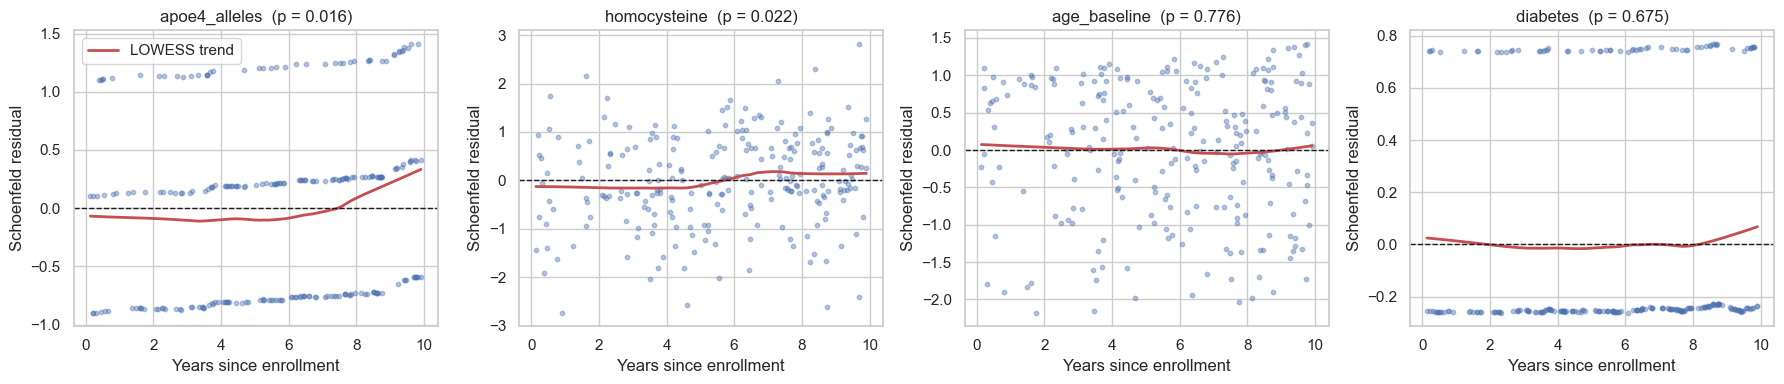

In [25]:
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess

# Schoenfeld residuals exist only for patients with the event (Alzheimer's)
is_event = (surv["event"] == 1).to_numpy()
schoenfeld = pd.DataFrame(
    cox.schoenfeld_residuals[is_event], columns=design.columns)
event_time = surv.loc[is_event, "time_years"].to_numpy()

# Test: does each variable's residual correlate with time?
rows = []
for var in design.columns:
    r, p = stats.pearsonr(stats.rankdata(event_time), schoenfeld[var])
    rows.append({"variable": var, "correlation with time": r, "p-value": p})
ph_test = pd.DataFrame(rows).set_index(
    "variable").sort_values("p-value").round(3)
display(ph_test)

# Plots for the key variables
show = ["apoe4_alleles", "homocysteine", "age_baseline", "diabetes"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, var in zip(axes, show):
    ax.scatter(event_time, schoenfeld[var], s=10, alpha=0.4)
    trend = lowess(schoenfeld[var], event_time, frac=0.6, it=0)
    ax.plot(trend[:, 0], trend[:, 1], color="C3", lw=2, label="LOWESS trend")
    ax.axhline(0, color="k", ls="--", lw=1)
    ax.set(title=f"{var}  (p = {ph_test.loc[var, 'p-value']:.3f})",
           xlabel="Years since enrollment", ylabel="Schoenfeld residual")
axes[0].legend()
plt.tight_layout()
plt.show()

### Notes – Proportional hazards (PH) assumption

#### 1. What was tested

- The Cox model assumes each **hazard ratio is constant over follow-up** (e.g., APOE4 multiplies the rate of Alzheimer's by the same amount in year 1 and in year 9).
- **Schoenfeld residuals:** for each Alzheimer's case (243), the difference between the patient's value of a variable and the average among patients **still at risk** at that time. If the HR is constant, these residuals show **no trend over time**.
- **Test:** correlation between residuals and the rank of event time (a simplified **Grambsch–Therneau** test). p < 0.05 suggests the HR changes over time.
- **Plots:** residuals over time with a LOWESS trend line. A **flat line at zero** means the assumption holds.

#### 2. Results

| Variable          | Correlation with time | p-value   | Assumption                              |
| ----------------- | --------------------- | --------- | --------------------------------------- |
| APOE4 alleles     | 0.155                 | **0.016** | ⚠️ Violated: effect increases over time |
| Homocysteine      | 0.147                 | **0.022** | ⚠️ Possibly violated (likely chance)    |
| Vitamin B12       | −0.095                | 0.141     | ✅                                      |
| Education         | 0.073                 | 0.257     | ✅                                      |
| HDL               | 0.067                 | 0.295     | ✅                                      |
| Hypertension      | 0.058                 | 0.364     | ✅                                      |
| BMI               | −0.057                | 0.376     | ✅                                      |
| CRP               | 0.055                 | 0.396     | ✅                                      |
| Smoking (current) | −0.042                | 0.515     | ✅                                      |
| Glucose           | −0.036                | 0.571     | ✅                                      |
| Systolic BP       | 0.035                 | 0.583     | ✅                                      |
| Creatinine        | −0.035                | 0.590     | ✅                                      |
| Diabetes          | 0.027                 | 0.675     | ✅                                      |
| HbA1c             | −0.019                | 0.769     | ✅                                      |
| Age               | −0.018                | 0.776     | ✅                                      |
| LDL               | 0.012                 | 0.852     | ✅                                      |
| Smoking (former)  | −0.012                | 0.854     | ✅                                      |
| Sex (male)        | −0.010                | 0.876     | ✅                                      |
| Depression        | −0.009                | 0.892     | ✅                                      |
| MMSE              | 0.004                 | 0.946     | ✅                                      |

#### 3. Interpretation

**A. The assumption holds for 18 of 20 variables.** Their HRs (step 21) can be interpreted as constant over the 10 years. In the plots, **age** and **diabetes** have flat trend lines close to zero.

**B. APOE4: the effect increases over follow-up (a real violation)**

- The trend line is flat until about year 7, then **rises**: APOE4's HR is **larger late in follow-up** than early.
- **Mechanism (built into the simulation):** APOE4 makes the MMSE decline faster each year, and each year's risk of Alzheimer's depends on that year's MMSE. The effect of APOE4 therefore **accumulates over time**.
- This is a realistic pattern: a risk factor acting through a **progressive process** (here, cognitive decline) can have an effect that grows with time.
- **Consequence:** the HR of 3.10 (step 21) is an **average** over the 10 years. It underestimates the effect late in follow-up and overestimates it early.

**C. Homocysteine: likely a chance finding**

- Nothing in the simulation makes its effect change over time.
- With 20 tests at α = 0.05, about one false positive is expected (**multiple comparisons**).
- With a Bonferroni correction (0.05 / 20 = 0.0025), **neither** APOE4 nor homocysteine would be significant. For APOE4, however, there is a known mechanism and a clear pattern in the plot. Statistical tests should be read together with plots and subject-matter knowledge.

**D. Size of the violations: modest.** Correlations of about 0.15 indicate small departures from proportionality. The Cox model remains useful; for APOE4, the most accurate statement is that its effect increases over follow-up.

#### 4. Reading the plots

- **APOE4 (3 bands)** and **diabetes (2 bands):** variables with few possible values produce horizontal bands of points. Look at the **trend line**, not the points.
- **LOWESS with `it=0`:** the non-robust version is used, because the robust version down-weights the smaller band of a binary variable and gives a misleading trend.

#### 5. Options when the assumption is violated

1. **Split follow-up into periods** (e.g., years 0–5 and 5–10) and estimate a separate HR for each.
2. **Add an interaction with time** (APOE4 × time), so the HR changes continuously.
3. **Stratify** by the variable (each level gets its own baseline hazard). This adjusts the other HRs correctly, but gives no HR for the stratified variable, so it is not useful for APOE4, the variable of interest.

#### 6. Limitations

- The test used here is a simplified version of the Grambsch–Therneau test (no global test across all variables).
- With 243 events, the test has limited power to detect small violations.


## 22. Cox model for death (competing event)

Same predictors and coding as step 21, but the event is now **death**; Alzheimer's and loss to follow-up are censored.
Question: which factors drive death? Are they the same as for Alzheimer's?


,0,1,2,3
0,Model:,PH Reg,Sample size:,1995
1,Dependent variable:,time_years,Num. events:,389
2,Ties:,Efron,,


,Alzheimer's: HR (95% CI),Alzheimer's p,Death: HR (95% CI),Death p
apoe4_alleles,3.10 (2.61–3.68),0.000,1.09 (0.92–1.29),0.333
diabetes,2.12 (1.35–3.31),0.001,1.47 (1.02–2.11),0.036
age_baseline,1.97 (1.70–2.28),0.000,1.78 (1.59–1.98),0.000
hypertension,1.52 (1.13–2.05),0.006,0.99 (0.78–1.25),0.926
depression,1.51 (1.07–2.14),0.020,0.76 (0.54–1.07),0.112
homocysteine,1.35 (1.18–1.55),0.000,0.98 (0.88–1.08),0.683
vitamin_b12,1.18 (1.03–1.35),0.014,1.01 (0.91–1.12),0.800
sex_M,1.07 (0.83–1.38),0.611,1.03 (0.84–1.26),0.768
systolic_bp,1.06 (0.91–1.24),0.421,1.04 (0.93–1.17),0.499
ldl,1.06 (0.94–1.21),0.345,1.09 (0.98–1.20),0.109


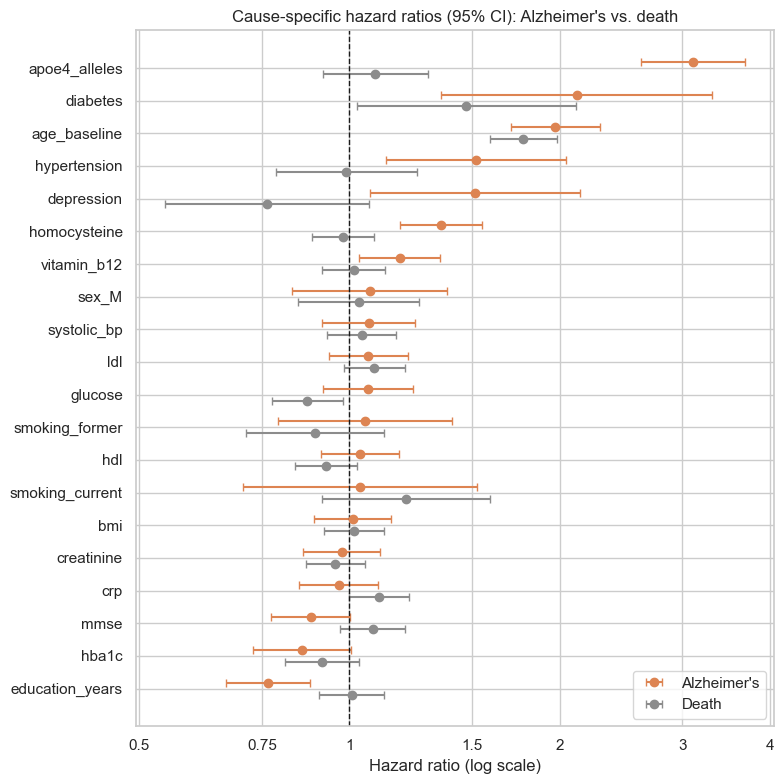

In [26]:
# Same design matrix as step 21; only the event changes (2 = death)
cox_death = PHReg(surv["time_years"], design,
                  status=(surv["event"] == 2).astype(int),
                  ties="efron").fit()

ci_d = np.exp(cox_death.conf_int())
hr_death = pd.DataFrame({
    "HR": np.exp(cox_death.params),
    "95% CI low": ci_d[:, 0],
    "95% CI high": ci_d[:, 1],
    "p-value": cox_death.pvalues,
}, index=design.columns)

display(cox_death.summary().tables[0])

# Side-by-side table: Alzheimer's (step 21) vs death


def hr_ci(t):
    return (t["HR"].map("{:.2f}".format) + " (" + t["95% CI low"].map("{:.2f}".format)
            + "–" + t["95% CI high"].map("{:.2f}".format) + ")")


order = hazard_ratios["HR"].sort_values(ascending=False).index
compare = pd.DataFrame({
    "Alzheimer's: HR (95% CI)": hr_ci(hazard_ratios),
    "Alzheimer's p": hazard_ratios["p-value"].round(3),
    "Death: HR (95% CI)": hr_ci(hr_death),
    "Death p": hr_death["p-value"].round(3),
}).loc[order]
display(compare)

# Forest plot
order_plot = hazard_ratios["HR"].sort_values().index
ypos = np.arange(len(order_plot))
fig, ax = plt.subplots(figsize=(8, 8))
for offset, (label, t, color) in zip([0.18, -0.18], [("Alzheimer's", hazard_ratios, "C1"),
                                                     ("Death", hr_death, "C7")]):
    t = t.loc[order_plot]
    ax.errorbar(t["HR"], ypos + offset,
                xerr=[t["HR"] - t["95% CI low"], t["95% CI high"] - t["HR"]],
                fmt="o", color=color, capsize=3, label=label)
ax.axvline(1, color="k", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3, 4])
ax.set_xticklabels(["0.5", "0.75", "1", "1.5", "2", "3", "4"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(ypos)
ax.set_yticklabels(order_plot)
ax.set(title="Cause-specific hazard ratios (95% CI): Alzheimer's vs. death",
       xlabel="Hazard ratio (log scale)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Notes – Cox model for death (competing event)

#### 1. Model setup

- **Event:** death (389 deaths; 1,995 patients contribute, because 5 left follow-up before the first death occurred)
- **Censored:** Alzheimer's diagnosis, loss to follow-up, end of study
- **Predictors and coding:** identical to the Alzheimer's model (step 21), so HRs can be compared row by row

#### 2. Results: Alzheimer's vs. death

| Variable              | Alzheimer's HR (95% CI) | p         | Death HR (95% CI)    | p         | Simulated effect on Alzheimer's / death |
| --------------------- | ----------------------- | --------- | -------------------- | --------- | --------------------------------------- |
| APOE4 (per allele)    | **3.10** (2.61–3.68)    | <0.001    | 1.09 (0.92–1.29)     | 0.333     | ✅ / ❌                                 |
| Diabetes              | **2.12** (1.35–3.31)    | 0.001     | 1.47 (1.02–2.11)     | **0.036** | ✅ / ❌ **false positive**              |
| Age (per SD)          | **1.97** (1.70–2.28)    | <0.001    | **1.78** (1.59–1.98) | <0.001    | ✅ / ✅                                 |
| Hypertension          | **1.52** (1.13–2.05)    | 0.006     | 0.99 (0.78–1.25)     | 0.926     | ✅ / ❌                                 |
| Depression            | **1.51** (1.07–2.14)    | 0.020     | 0.76 (0.54–1.07)     | 0.112     | ✅ / ❌                                 |
| Homocysteine (per SD) | **1.35** (1.18–1.55)    | <0.001    | 0.98 (0.88–1.08)     | 0.683     | ✅ / ❌                                 |
| Vitamin B12 (per SD)  | 1.18 (1.03–1.35)        | **0.014** | 1.01 (0.91–1.12)     | 0.800     | ❌ **false positive** / ❌              |
| Sex (male)            | 1.07 (0.83–1.38)        | 0.611     | 1.03 (0.84–1.26)     | 0.768     | ❌ / ❌                                 |
| Systolic BP           | 1.06 (0.91–1.24)        | 0.421     | 1.04 (0.93–1.17)     | 0.499     | ❌ / ❌                                 |
| LDL                   | 1.06 (0.94–1.21)        | 0.345     | 1.09 (0.98–1.20)     | 0.109     | ❌ / ❌                                 |
| Glucose               | 1.06 (0.92–1.23)        | 0.416     | 0.87 (0.77–0.98)     | **0.020** | ❌ / ❌ **false positive**              |
| Smoking (former)      | 1.05 (0.79–1.40)        | 0.734     | 0.89 (0.71–1.12)     | 0.325     | ❌ / ❌                                 |
| HDL                   | 1.04 (0.91–1.18)        | 0.583     | 0.93 (0.84–1.03)     | 0.139     | ❌ / ❌                                 |
| Smoking (current)     | 1.03 (0.70–1.52)        | 0.861     | 1.20 (0.91–1.59)     | 0.188     | ❌ / ❌                                 |
| BMI                   | 1.01 (0.89–1.15)        | 0.866     | 1.02 (0.92–1.12)     | 0.765     | ❌ / ❌                                 |
| Creatinine            | 0.97 (0.86–1.11)        | 0.691     | 0.95 (0.86–1.05)     | 0.345     | ❌ / ❌                                 |
| CRP                   | 0.96 (0.85–1.10)        | 0.584     | 1.10 (1.00–1.22)     | 0.055     | ❌ / ❌                                 |
| MMSE (per SD)         | 0.88 (0.77–1.00)        | 0.054     | 1.08 (0.97–1.20)     | 0.161     | ✅ / ❌                                 |
| HbA1c                 | 0.86 (0.73–1.01)        | 0.059     | 0.91 (0.81–1.03)     | 0.147     | ❌ / ❌                                 |
| Education (per SD)    | **0.76** (0.67–0.88)    | <0.001    | 1.01 (0.91–1.12)     | 0.895     | ✅ / ❌                                 |

#### 3. Interpretation

**A. APOE4 is specific to Alzheimer's**

- Death HR = 1.09 (95% CI 0.92–1.29, includes 1): **no association with death**, while it triples the rate of Alzheimer's.
- This is the largest contrast in the forest plot. APOE4 raises the risk of dementia, not of dying from other causes.

**B. Age drives both outcomes**

- HR 1.97 for Alzheimer's and 1.78 for death (both p < 0.001).
- **Age is what makes the two events compete:** older patients are at higher risk of Alzheimer's, but also more likely to die before developing it. This explains why the competing-risks bias was largest in high-risk groups (step 20).

**C. Other factors are specific to Alzheimer's**

- Hypertension, depression, homocysteine and education are associated with Alzheimer's only; their confidence intervals for death include 1.

**D. False positives (multiple comparisons)**

- **Death model:** diabetes (HR 1.47, p = 0.036) and glucose (HR 0.87, p = 0.020). Neither affects death in the simulation.
  - They point in **opposite directions** and are correlated with each other (rho ≈ 0.53, step 9), which is a typical pattern of a chance finding split between collinear variables.
- **Alzheimer's model:** vitamin B12 (step 21).
- With **40 tests** across the two models at α = 0.05, about **2 false positives** are expected by chance; **3** were observed.

#### 4. Why model the competing event?

The effect of a factor on the **real probability** of Alzheimer's depends on how it affects **both** events:

| Factor affects…            | Effect on observed probability of Alzheimer's                            | Example here                                             |
| -------------------------- | ------------------------------------------------------------------------ | -------------------------------------------------------- |
| Alzheimer's only           | Increases it, as the HR suggests                                         | APOE4, hypertension, homocysteine                        |
| Both Alzheimer's and death | **Weaker** than the HR suggests, because some at-risk patients die first | Age                                                      |
| Death only                 | **Decreases** it, even with no biological effect on Alzheimer's          | None here (would be a classic trap in older populations) |

#### 5. Reading the forest plot

- Each point is an HR; horizontal lines are 95% CIs. The dashed line (HR = 1) means no effect.
- **Log scale:** HR = 2 and HR = 0.5 are the same distance from 1, because they are effects of equal size in opposite directions.
- A CI crossing the dashed line = no clear association.

#### 6. Limitations

- **Cause-specific HRs** describe effects on the rate of each event among patients still event-free. They do not directly give the real probability of each event (that requires cumulative incidence, step 20, or a Fine–Gray model).
- No correction for multiple testing.
- The proportional hazards assumption was checked for the Alzheimer's model only (step 22), not for the death model.
- Simulated data: results validate the method; they are not clinical findings.


# Study summary

## 1. Design

- **Simulated prospective cohort:** 2,000 patients aged 60–80, enrolled in 2014–2015, annual visits for up to 10 years.
- **Data source:** SQLite database with 4 linked tables: `patients` (demographics, APOE4), `visits` (MMSE, BMI, BP, comorbidities), `labs` (8 tests, long format), `events` (Alzheimer's, death, loss to follow-up).
- **Follow-up:** 14,363 person-years (median 9.1 years).

| How follow-up ended   | Patients |
| --------------------- | -------- |
| Alzheimer's diagnosis | 243      |
| Death                 | 389      |
| Lost to follow-up     | 470      |
| Completed 10 years    | 898      |

- **Predictors:** baseline (enrollment) data only, to avoid leakage from the future.

## 2. Data quality

- No duplicates, broken links between tables or missing cells.
- **Lab completeness:** 91.9% of possible tests performed (missing tests are absent rows in long format, invisible to `isna()`).
- **430 physiologically implausible lab values** (e.g., vitamin B12 < 100 pg/mL) set to missing using plausibility limits.

## 3. Descriptive findings

- Patients who developed Alzheimer's were **older** (median 73.5 vs. 67.6 years), carried **more APOE4 alleles** (59% vs. 24% with ≥ 1 allele), had **less education** and more **diabetes, hypertension and depression**.
- **MMSE declined faster** in patients who developed Alzheimer's, starting years before diagnosis (preclinical phase).
- **Correlations between predictors** were moderate at most (|rho| ≤ 0.55): no serious multicollinearity.

## 4. Prediction: Alzheimer's within 10 years (machine learning)

- **Cohort:** 1,141 patients (243 cases, 898 Alzheimer's-free after 10 years); 859 who died or were lost were excluded (status unknown).
- **Split:** 75% train / 25% test, stratified; 5-fold cross-validation on train; test set used once.

| Model               | Test AUC (95% CI)       | Average precision | Brier score |
| ------------------- | ----------------------- | ----------------- | ----------- |
| Logistic regression | 0.810 (0.746–0.868)     | **0.596**         | **0.127**   |
| XGBoost             | 0.803 (0.741–0.863)     | 0.533             | 0.134       |
| LightGBM            | 0.810 (0.749–0.866)     | 0.551             | 0.132       |
| CatBoost            | **0.813** (0.753–0.867) | 0.557             | 0.130       |

- **All four models are equivalent** (overlapping CIs); no overfitting (test ≈ cross-validation AUC); calibration acceptable.
- **Logistic regression is preferred:** marginally better precision and Brier score, simplest and most interpretable. Consistent with the logistic, additive structure of the simulated data.
- **Explanation:** odds ratios and SHAP values agree on the main predictors: **APOE4 and age**, then homocysteine, education and MMSE. Built-in **gain importance was unreliable** (it ranked noise variables above real binary risk factors).

## 5. Survival analysis: all 2,000 patients

- **Incidence rate:** 16.9 Alzheimer's cases per 1,000 person-years.
- **10-year cumulative incidence** (death as competing risk): **14.7%** overall; 8.7% / 23.8% / 48.1% for 0 / 1 / 2 APOE4 alleles. Death: 23.0%.
- **Cause-specific Cox models (HR, 95% CI):**

| Factor                | Alzheimer's          | Death                |
| --------------------- | -------------------- | -------------------- |
| APOE4 (per allele)    | **3.10** (2.61–3.68) | 1.09 (0.92–1.29)     |
| Age (per SD)          | **1.97** (1.70–2.28) | **1.78** (1.59–1.98) |
| Diabetes              | **2.12** (1.35–3.31) | 1.47 (1.02–2.11)\*   |
| Hypertension          | **1.52** (1.13–2.05) | 0.99 (0.78–1.25)     |
| Depression            | **1.51** (1.07–2.14) | 0.76 (0.54–1.07)     |
| Homocysteine (per SD) | **1.35** (1.18–1.55) | 0.98 (0.88–1.08)     |
| Education (per SD)    | **0.76** (0.67–0.88) | 1.01 (0.91–1.12)     |

\* false positive (no simulated effect)

- **APOE4 is specific to Alzheimer's**; **age drives both** outcomes and is what makes them compete.
- **Proportional hazards** held for 18 of 20 variables. **APOE4's effect increases over follow-up** (it acts through progressive MMSE decline), so its HR of 3.10 is an average over 10 years.

## 6. Ten-year risk of Alzheimer's: how the method changes the answer

| Method                                    | Estimate  | Bias                                          |
| ----------------------------------------- | --------- | --------------------------------------------- |
| Simple proportion (243 / 2,000)           | 12.2%     | Underestimates (ignores incomplete follow-up) |
| Logistic cohort prevalence (243 / 1,141)  | 21.3%     | Overestimates (survivor-only controls)        |
| Naive 1 − Kaplan–Meier                    | 17.2%     | Overestimates (treats death as censoring)     |
| **Cumulative incidence, competing risks** | **14.7%** | **Correct**                                   |

## 7. Methodological lessons

1. **Avoid leakage:** use only information available at the time of prediction; keep imputation and scaling inside pipelines; lock the test set until the end.
2. **"No missing values" ≠ clean data:** check plausible ranges, and remember that missing rows in long format are invisible to `isna()`.
3. **A more complex model is not automatically better:** logistic regression matched the boosting models.
4. **Feature importance needs care:** gain importance is biased toward continuous variables; SHAP and odds ratios are more reliable. SHAP explains the model, not the disease.
5. **p-values need care:** with many tests, false positives appear (vitamin B12, diabetes and glucose for death), and real effects can miss p < 0.05 (MMSE). Read effect sizes and confidence intervals.
6. **Competing risks matter** in older populations: ignoring death overestimates the risk of Alzheimer's, most in the highest-risk groups.
7. **ORs are larger than HRs** when the outcome is common and when the cohort is restricted to survivors.

## 8. Limitations

- **Simulated data:** results validate the pipeline and methods; they are not clinical findings.
- **Prediction cohort excludes 43%** of patients (died or lost) → performance likely optimistic for real-world use.
- **Baseline-only predictors:** changes over follow-up (e.g., MMSE decline) were not used for prediction.
- **Simple median imputation**; hyperparameters not tuned; no decision threshold chosen.
- **No correction for multiple testing.**
- **Non-informative censoring assumed** for patients lost to follow-up.
- **No Fine–Gray model** (not available in statsmodels): cause-specific HRs describe rates, not probabilities.

## 9. Possible next steps

- APOE4 hazard ratio by period (0–5 vs. 5–10 years) or APOE4 × time interaction.
- **Landmark model:** predict from year 2 using change between visits (e.g., MMSE slope).
- Decision threshold with sensitivity, specificity and PPV, chosen without the test set.
- Fine–Gray model; multiple imputation; hyperparameter tuning; validation by study site.


---

# Exercises

The sections above answer their own questions. These do not: there are no solutions
below, on purpose. Each one tests a claim this notebook makes, so the point is not to
produce a number but to decide whether the claim survives.

### 1. Choose a decision threshold

Section 16 reports AUC, average precision and Brier score, but never picks a cut-off,
so it never answers the question a clinic actually asks: who gets flagged?

Using **only** the training set, find the threshold that reaches at least 80%
sensitivity. Then apply that threshold, unchanged, to the test set and report
sensitivity, specificity, PPV and NPV.

_Hint:_ `cross_val_predict(logreg, X_train, y_train, cv=cv, method="predict_proba")`
gives out-of-fold probabilities for the training set.

_The question:_ why must the threshold be chosen before the test set is touched, when
the test set would obviously give a better-looking number?

### 2. Is gain importance really biased?

Section 14 asserts that built-in gain importance ranked noise above real binary risk
factors. Asserting it is weaker than showing it.

Add a column of pure random noise to `FEATURES`, refit LightGBM, and compare where the
noise lands in gain importance against where it lands in mean |SHAP|. Then change the
seed of the noise and refit.

_The question:_ if the noise column moves several positions between seeds, what does
that say about reading any single feature-importance ranking as a finding?

### 3. What do the exclusions cost?

Section 10 drops 43% of patients because their ten-year status is unknown, and the
limitations warn that this makes performance optimistic.

Build a second modelling cohort that also counts as controls the patients followed for
at least five years without Alzheimer's. Refit the logistic model and compare AUC and
average precision against the original.

_The question:_ the numbers will move. Does a higher AUC here mean the model got better?

### 4. APOE4 and the assumption that failed

Section 21 found that the effect of APOE4 grows over follow-up, which is exactly what a
single hazard ratio cannot express. The notebook reports HR 3.10 anyway, calling it an
average over ten years.

Split follow-up at five years and fit the cause-specific Cox model separately in each
window. Compare the two hazard ratios with the pooled 3.10.

_The question:_ if the two windows disagree, what is the pooled 3.10 the average of, and
would you put it in a paper without the split?
